# To Fix:
1. heisenberg plot fails when no_levels of WPT is 1 / 2/ 3
2. add kurtosis, crest factor, entropy, energy, etc calculations to utils as functions to be loaded as methods. They shouldn't be in test. Test folder usually contains codes for unit and integration tests not utilities.
3. calculate energy using WPT coefficients not reconstructed data at each node

https://sapienlabs.org/lab-talk/measuring-entropy-in-the-eeg/


In [1]:
import sys

if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

In [2]:
sys.path.append("..")
from wavelet_transform.wpt import transform as wpt
from wavelet_transform.test import synthetic_data as sd
from wavelet_transform.wpt import inverse_transform as inv
from wavelet_transform.postprocess import plotting as plot

# import matplotlib
# matplotlib.use('nbagg')
import matplotlib.pyplot as plt
import numpy as np
import pywt
import scipy.stats as sc

### Parameters

Specify parameters for synthetic data and wavelet transform

In [3]:
# keep the same
sampling_rate = 100  # unit: Hz

# PARAMETERS TO CHANGE
amplitudes = [0.4, 1, 0.7]  # amplitude of each sine wave
frequencies = [5, 10, 25]  # frequency content of signal
phases = [0, np.deg2rad(45), 0]  # phase of each sine wave

duration = 1000 / min(frequencies)  # duration of wave

trans_amp = [3 for _ in range(3)]  # amplitudes of transients
n_trans = len(trans_amp)  # number of transients
trans_dur = [0.05 for _ in range(n_trans)]  # duration of transients
trans_time = [
    duration * i / (n_trans + 1) for i in range(1, n_trans + 1)
]  # times of transients

std_noise = 0.1

wavelet = "db20"
levels = 5
mode = "symmetric"

sort_by = 'energy'  # 'energy', 'kurtosis', 'crest', 'False' -> freq
sort = "rec"  # 'rec' (reconstructed signal) 'coef' (transform coefficients)
# n_highest = 3

fft_lim = 50  # increase value to view more of the fft plots

### Generating synthetic data

Generate synthetic data with transients, noise, and harmonics. Plot the data with its FFT. 

/tmp/ipykernel_49816/1155838967.py:22: MatplotlibDeprecationWarning: The 'use_line_collection' parameter of stem() was deprecated in Matplotlib 3.6 and will be removed two minor releases later. If any parameter follows 'use_line_collection', they should be passed as keyword, not positionally.
  ax[1].stem(


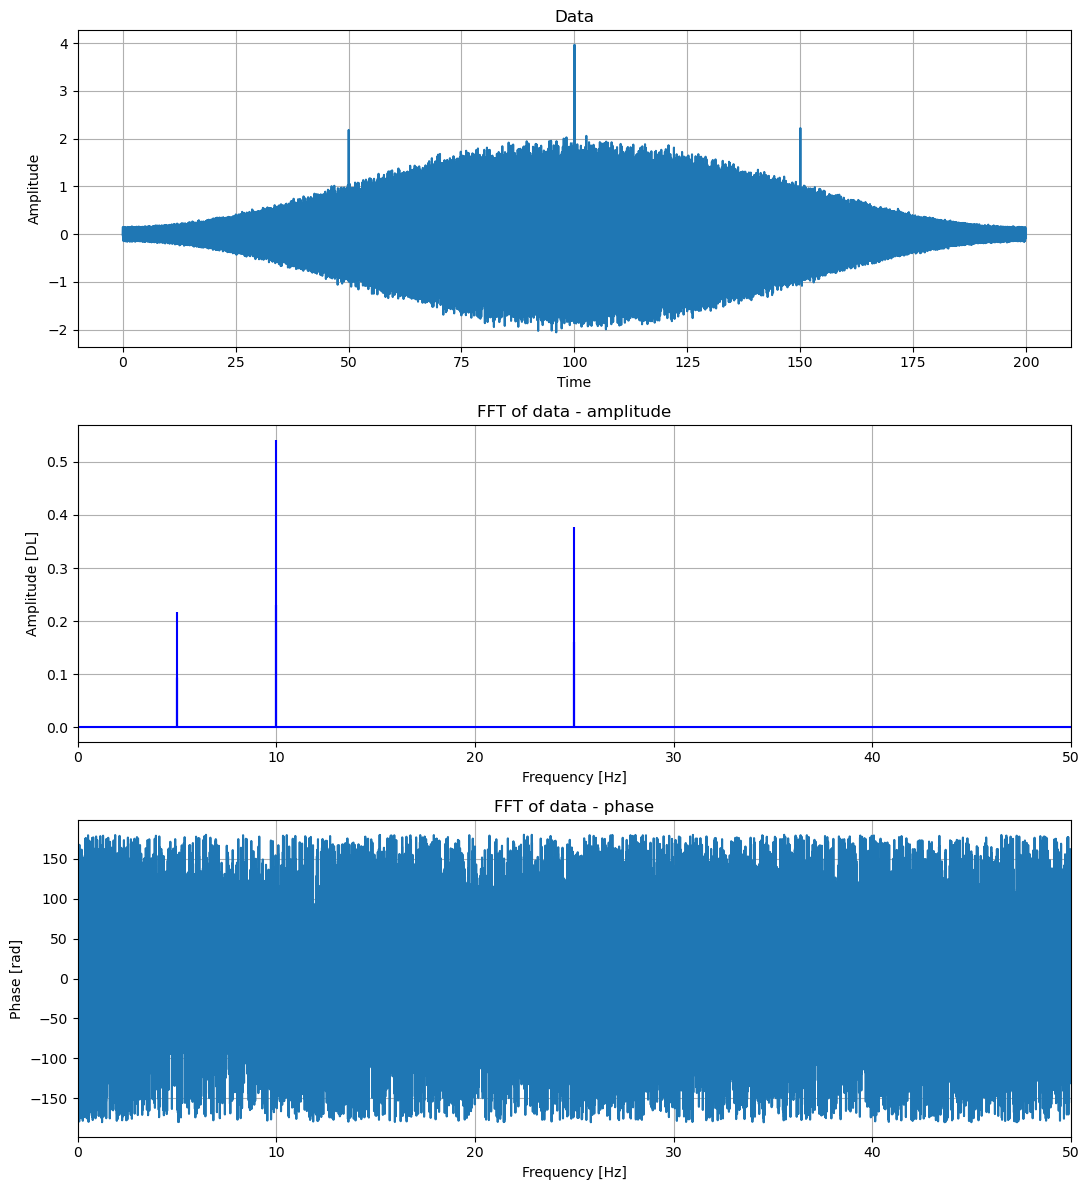

In [4]:
# generate sound wave
data, t_plot = sd.sound_wave(amplitudes, frequencies, phases, duration, sampling_rate)
signal_length = len(data)
transient_signal = sd.transients(trans_amp, trans_time, trans_dur, duration, sampling_rate)
data += transient_signal
data += sd.noise(std_noise,duration,sampling_rate)
data *= np.hamming(signal_length)

fft_data = np.fft.fft(data)[0 : int(signal_length / 2)] / (
    signal_length / 2
)  # division by signal_length/2 is to correct the amplitude (energy) in the freq domain
freq = np.fft.fftfreq(signal_length, d=1 / sampling_rate)[0 : int(signal_length / 2)]

# plot sound wave and fft
fig, ax = plt.subplots(3, figsize=(11, 12))
ax[0].plot(t_plot, data)
ax[0].set_title("Data")
ax[0].set_xlabel("Time")
ax[0].set_ylabel("Amplitude")
ax[0].grid()

ax[1].stem(
    freq,
    np.abs(fft_data),
    linefmt="b",
    markerfmt=" ",
    basefmt="-b",
    use_line_collection=True,
)
ax[1].set_title("FFT of data - amplitude")
ax[1].set_xlabel("Frequency [Hz]")
ax[1].set_ylabel("Amplitude [DL]")
ax[1].set_xlim(0, sampling_rate / 2)
ax[1].grid()

ax[2].plot(freq, np.angle(fft_data, deg=True))
ax[2].set_title("FFT of data - phase")
ax[2].set_xlabel("Frequency [Hz]")
ax[2].set_ylabel("Phase [rad]")
ax[2].set_xlim(0, sampling_rate / 2)
ax[2].grid()
fig.tight_layout()
plt.show()

Calculating crest factor and energy

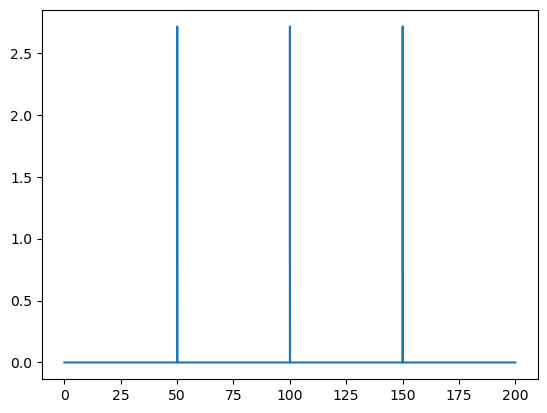

In [5]:
plt.plot(t_plot,transient_signal)
plt.show()

In [6]:
def calc_crest_factor(array):
    rms = (np.sqrt(1 / len(array) ) * sum(array**2))
    return 10 * np.log10(max(array**2) / rms)


def calc_energy(array):
#     return 1 / len(array) * sum(array**2)
    return np.var(array)

Wavelet transform

In [7]:
# WPT transform
tr_ob = wpt.dwpt(data, levels, wavelet, mode)
tr_ob.calc_frequencies(sampling_rate)

# reconstruct each node separately
rec = []

total_energy = calc_energy(data)

# calculate energy, kurtosis, and crest factor of reconstructed signals
for node in tr_ob.get_level(order="freq"):
    path = node.path
    rec_nodes = tr_ob.packet_nodes_for_rec(keep=[path])
    coeffs = tr_ob.nodes2data(rec_nodes)
    inverse = inv.inv_dwpt(coeffs, wavelet)[:signal_length]
    inverse_signal_length = len(inverse)
    fft = np.fft.fft(inverse)[0 : int(inverse_signal_length / 2)] / (
        inverse_signal_length * 0.5
    )
    energy = calc_energy(inverse)
    energy_relative = energy / total_energy
    entropy_node = energy_relative * np.log2(energy_relative)
    kurtosis = sc.kurtosis(inverse)
    skewness = sc.skew(inverse)
    crest = calc_crest_factor(inverse)
    rec.append((node, inverse, fft, energy, kurtosis, crest, entropy_node, skewness))

### Heisenberg visualisation

Making the heisenberg plot of the dwpt transform

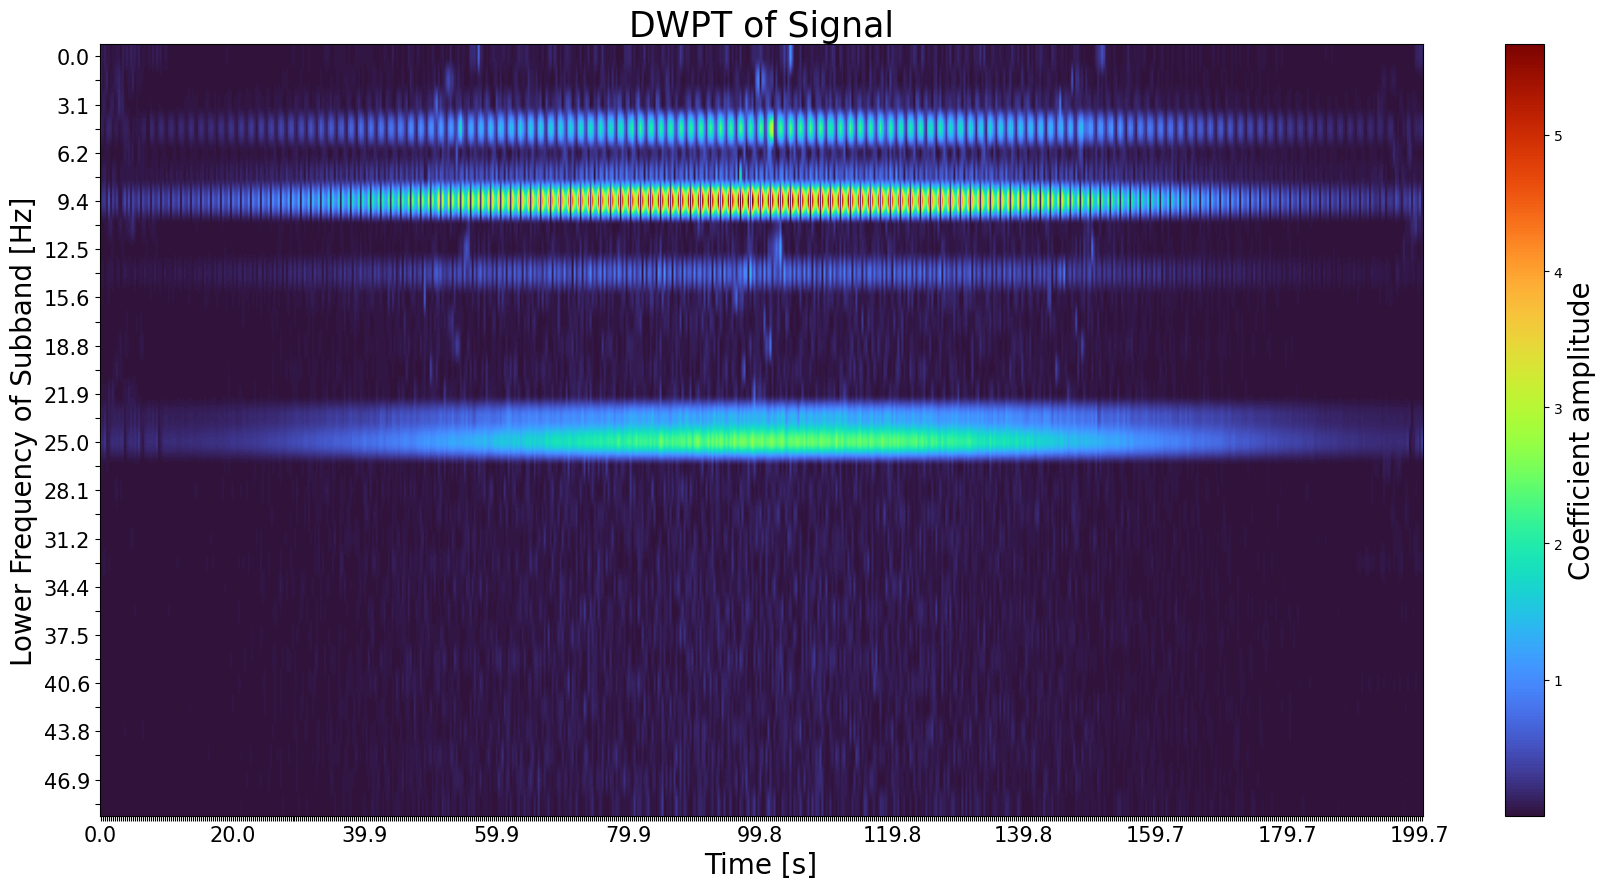

In [8]:
plot.heisenberg(tr_ob, max(t_plot))

### K-means

k-means clustering on the calculated statistics from the output of the DWPT

In [9]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np

# training data
data_train = []
for _, inverse, _, energy, kurtosis, crest, entropy_node, skewness in rec:
#     data_train.append(
#         (energy, kurtosis, crest, max(abs(inverse)), 
#         np.mean(inverse), sc.skew(inverse))
#         )
    data_train.append(
        (energy, kurtosis, skewness)
        )

scaler = StandardScaler()
data_train_normalised = scaler.fit_transform(data_train)

# training k-means algorithm
no_clusters = 3
kmeans = KMeans(n_clusters=no_clusters)
kmeans.fit(data_train_normalised)

# get labels and clusters
labels = kmeans.labels_
centers = scaler.inverse_transform(kmeans.cluster_centers_)

/home/optimus2017/anaconda3/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


In [10]:
data_train

[(0.0002557810695914389, 37.52840453133968, 3.666447922771729),
 (0.0002731300920022798, 71.73998009835756, 0.7338890169564452),
 (0.0009355970051034074, 1.718253115873214, 0.008602282233869976),
 (0.03135216778630586, 0.09787269822798006, 2.240135497312832e-05),
 (0.0008755179443553615, 2.0490719304729454, -0.00022022434073259886),
 (0.004792566045771798, 0.36576524651182174, 0.003900138574687524),
 (0.19089358869212866, -0.02274721757455067, 6.527506247941599e-06),
 (0.00015680242908620718, 8.110755467898388, -8.407461946340766e-05),
 (0.0003236083631897, 125.8437899170718, 2.3868627049606892e-05),
 (0.004740766087088476, 0.37618053004505203, 1.8686943425315738e-05),
 (0.0002841072627803591, 10.332959568422451, -0.03022596659925308),
 (0.00015106159265859952, 5.597893553975474, -3.5421811265952283e-06),
 (0.00016585744254888596, 33.50783416907767, 4.044063994216955e-05),
 (0.00014654352698927864, 6.525124307888705, -0.0002490901018263064),
 (0.00016753138674185667, 19.56091638188729,

### Reassigning Groups

Post-hoc reassignment of groups based on the energy and kurtosis of their clusters.

In [11]:
def assign_labels(centers, labels, sort_by=1):
    """
    assign labels to clusters. Assign the highest cluster number to the centre with 
    highest energy. Then assign the rest in order of sort_by. The group numbers are reassigned
    to 1-indexed groups.

    Paramaters
    -----------
    centers: array
        array where each row is a centre of a cluster
    labels: list
        list of group assignments to reassign
    sort_by: int
        always sort out the highest energy because the harmonic can be separated
        from the rest by its much greater energy. Otherwise, sort by attribute
        number = sort_by of the centres. e.g. sort_by == 1 will sort the rest 
        by kurtosis, sort_by == 2 will sort by crest factor etc.
    """
    # sort labels by energy, highest cluster energy is highest group number
    sort_by_energy = np.argsort(centers[:, 0])

    # sort rest of the labels by kurtosis
    sort_rest = np.argsort(centers[:, sort_by])

    sort_rest = np.delete(
        sort_rest, # delete highest energy group form kurtosis
        np.where(sort_rest == sort_by_energy[-1])[0][0], 
        axis=0
        )
    sort_rest = np.append(sort_rest, None)

    # create mapping from old cluster labels to new cluster labels
    mapping = {}
    for new_label, index in enumerate(zip(sort_by_energy, sort_rest)):
        if new_label == len(sort_by_energy) - 1:  # highest group no has highest energy
            mapping[index[0]] = new_label + 1
        else:
            mapping[index[1]] = new_label + 1  # other group numbers are arranged by kurtosis

    # update labels
    reassigned_labels = [mapping[label] for label in labels]
    return reassigned_labels

In [12]:
reassigned_labels = assign_labels(centers, labels)

### Plot result

Plot the assigned group against the frequency of the node. 

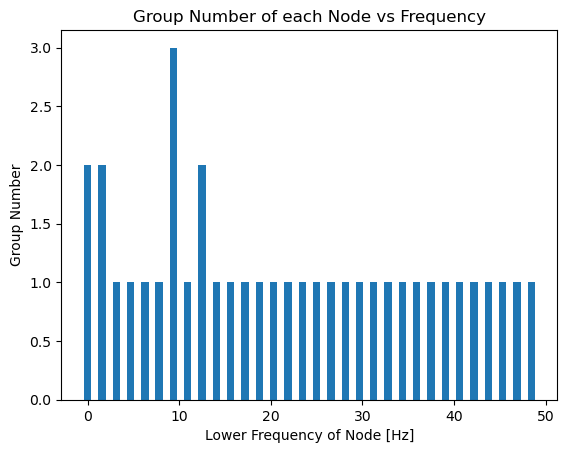

In [13]:
# plot regular k-means
plt.bar([node.frequency_range[0] for node,*_ in rec], reassigned_labels)
plt.title('Group Number of each Node vs Frequency')
plt.xlabel('Lower Frequency of Node [Hz]')
plt.ylabel('Group Number')
plt.show()

### PCA

PCA is applied to reduce the dimenisonality of the input features before performing k-means. The centers are converted back to pre-PCA coordinates. The group numbers are sorted based on energy and kurtosis.

In [14]:
# apply PCA to training data
pca = PCA(n_components=len(data_train[0]))
data_pca = pca.fit_transform(data_train_normalised)

# training k-means algorithm on the reduced data
kmeans_pca = KMeans(n_clusters=no_clusters)
kmeans_pca.fit(data_pca)

# convert centres back to regular feature space (energy, kurtosis, crest, etc.)
labels_pca = kmeans_pca.labels_
centers_pca = scaler.inverse_transform(pca.inverse_transform(kmeans_pca.cluster_centers_))
reassigned_pca_labels = assign_labels(centers_pca, labels_pca)

/home/optimus2017/anaconda3/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


### Plot PCA result

The group number vs frequency for each node is plotted again after PCA is applied.

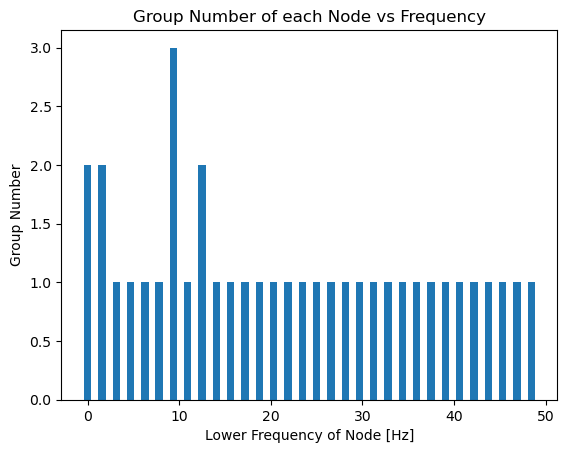

Eigenvectors:
energy, kurtosis, skewness
[[-0.4   0.67  0.62]
 [ 0.89  0.13  0.43]
 [ 0.21  0.73 -0.65]]
Eigenvalues: [1.37 0.98 0.75]


In [15]:
# plot pca k-means
lower_freqs = [node.frequency_range[0] for node,*_ in rec]
plt.bar([node.frequency_range[0] for node,*_ in rec], reassigned_pca_labels)
plt.tick_params
plt.title('Group Number of each Node vs Frequency')
plt.xlabel('Lower Frequency of Node [Hz]')
plt.ylabel('Group Number')
plt.show()

eigenvectors = pca.components_
eigenvalues = pca.explained_variance_

print("Eigenvectors:")
print('energy, kurtosis, skewness')
print(np.round(eigenvectors,2))

print("Eigenvalues:", np.round(eigenvalues,2))

### 3d plot

3d plots of the clustering results with axes: energy, kurtosis, crest factor

/tmp/ipykernel_49816/2037609382.py:7: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('Set1')


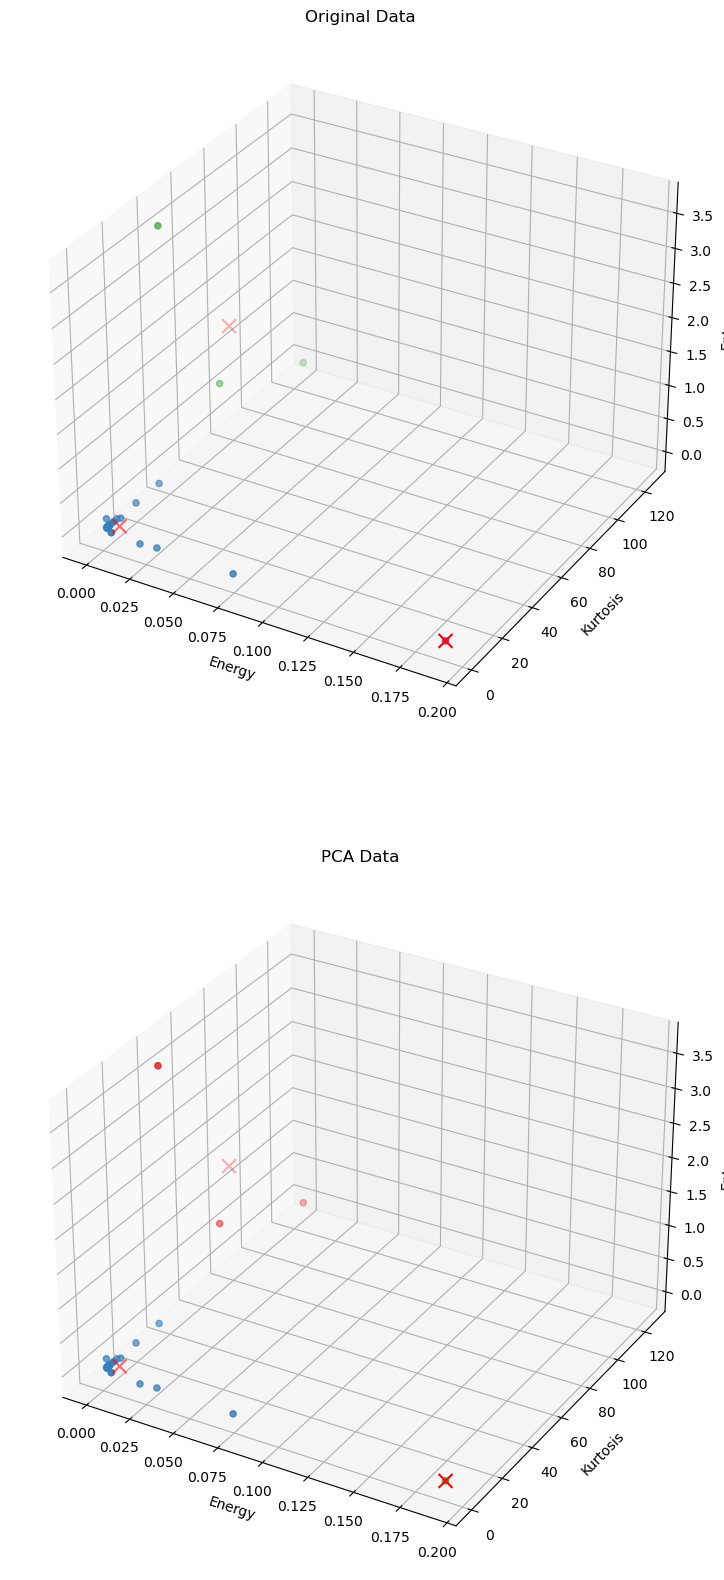

In [16]:
fig, ax = plt.subplots(2, figsize=(20, 20), subplot_kw={'projection': '3d'})

titles = ['Original Data', 'PCA Data']

# plot subplots for PCA data and non-PCA data
for i, ax in enumerate(ax):
    cmap = plt.cm.get_cmap('Set1')
    if i == 0:
        data_scatter = data_train
        centers_scatter = centers
        labels_scatter = reassigned_labels
    else:
        data_scatter = data_train
        centers_scatter = centers_pca
        labels_scatter = labels_pca

    ax.scatter(
        [point[0] for point in data_scatter],
        [point[1] for point in data_scatter],
        [point[2] for point in data_scatter],
        c=[cmap(label) for label in labels_scatter])
    ax.scatter(
        centers_scatter[:, 0],
        centers_scatter[:, 1],
        centers_scatter[:, 2],
        c='red', marker='x', s=100)
    
    ax.set_xlabel('Energy')
    ax.set_ylabel('Kurtosis')
    ax.set_zlabel('Entropy')
    ax.set_title(titles[i])

plt.show()

### Results

Plotting the reconstructed waves at each node alongside their assigned group number.

In [17]:
def plot_reconstructions(rec, group=None):
    for i, rec in enumerate(rec):  # highest energy, kurtosis, etc.
        node, rec_wave, fft, *_ = rec
        fig, ax = plt.subplots(
            2, figsize=(11, 8)
        )  # plot reconstructed wave and its fft
        freq_r = node.frequency_range
        ax[0].plot(t_plot, rec_wave)
        title = f"Reconstructed subband [{freq_r[0]}- {freq_r[1]} Hz]"
        if group is not None:
            title = f"Reconstructed subband [{freq_r[0]}- {freq_r[1]} Hz] group: {group[i]}"
        ax[0].set_title(title)
        ax[0].set_xlabel("time")
        ax[0].set_ylabel("amplitude")
        ax[1].stem(
            freq,
            np.abs(fft),
            linefmt="b",
            markerfmt=" ",
            basefmt="-b",
            use_line_collection=True,
        )
        ax[1].set_title("FFT of reconstructed subband")
        ax[1].set_xlabel("Frequency")
        ax[1].set_ylabel("Power")
        ax[1].set_xlim(
            max(0, freq_r[0] - fft_lim), min(sampling_rate / 2, freq_r[1] + fft_lim)
        )
        ax[1].grid()
        fig.tight_layout()
        plt.show()

        # print info
        print(f"energy of recovered signal: {calc_energy(rec_wave)}")
        print(f"kurtosis of recovered signal: {sc.kurtosis(rec_wave)}")
        print(f"crest factor of recovered signal: {calc_crest_factor(rec_wave)}")
        print()
        print(f"energy of node coefficients: {node.energy}")
        print(f"kurtosis of node coefficients: {node.kurtosis}")
        print(f"crest factor of node coefficients: {node.crest_factor}")

Change to group=reassign_pca_labels to display the groups assigned using PCA

/tmp/ipykernel_49816/4227367065.py:15: MatplotlibDeprecationWarning: The 'use_line_collection' parameter of stem() was deprecated in Matplotlib 3.6 and will be removed two minor releases later. If any parameter follows 'use_line_collection', they should be passed as keyword, not positionally.
  ax[1].stem(


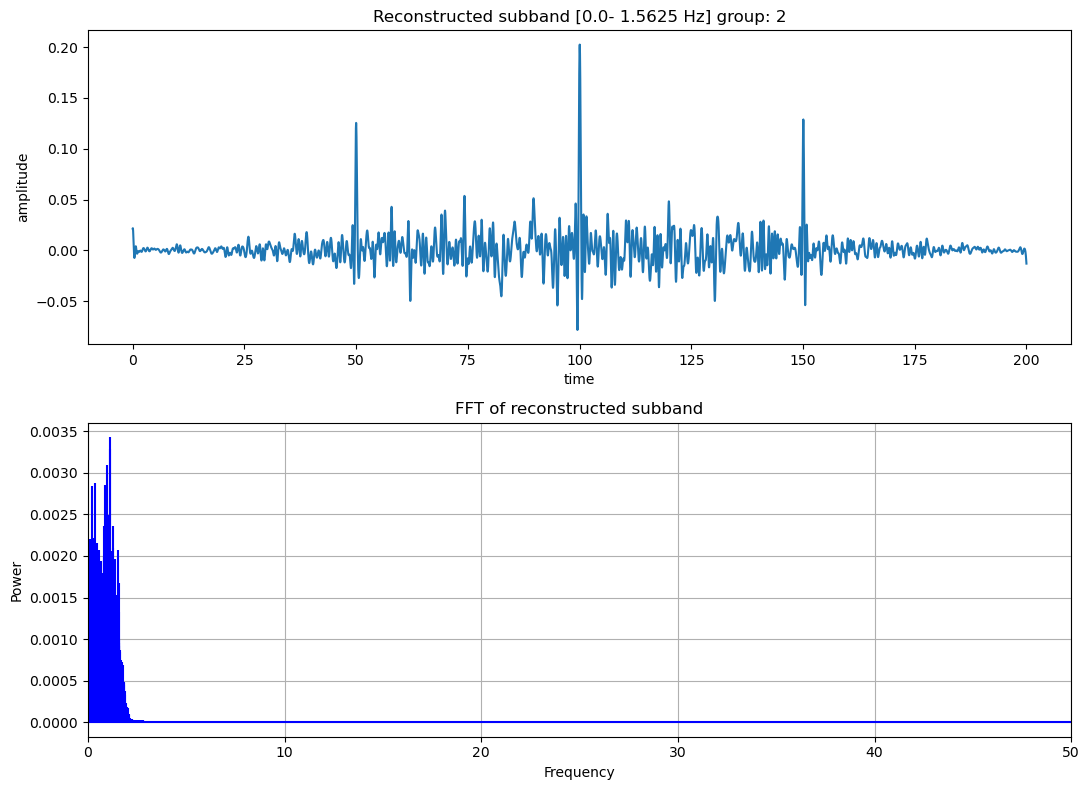

energy of recovered signal: 0.0002557810695914389
kurtosis of recovered signal: 37.52840453133968
crest factor of recovered signal: 0.5282602802244408

energy of node coefficients: 0.008100475003686448
kurtosis of node coefficients: 32.374863854833634
crest factor of node coefficients: 10.880555262189585


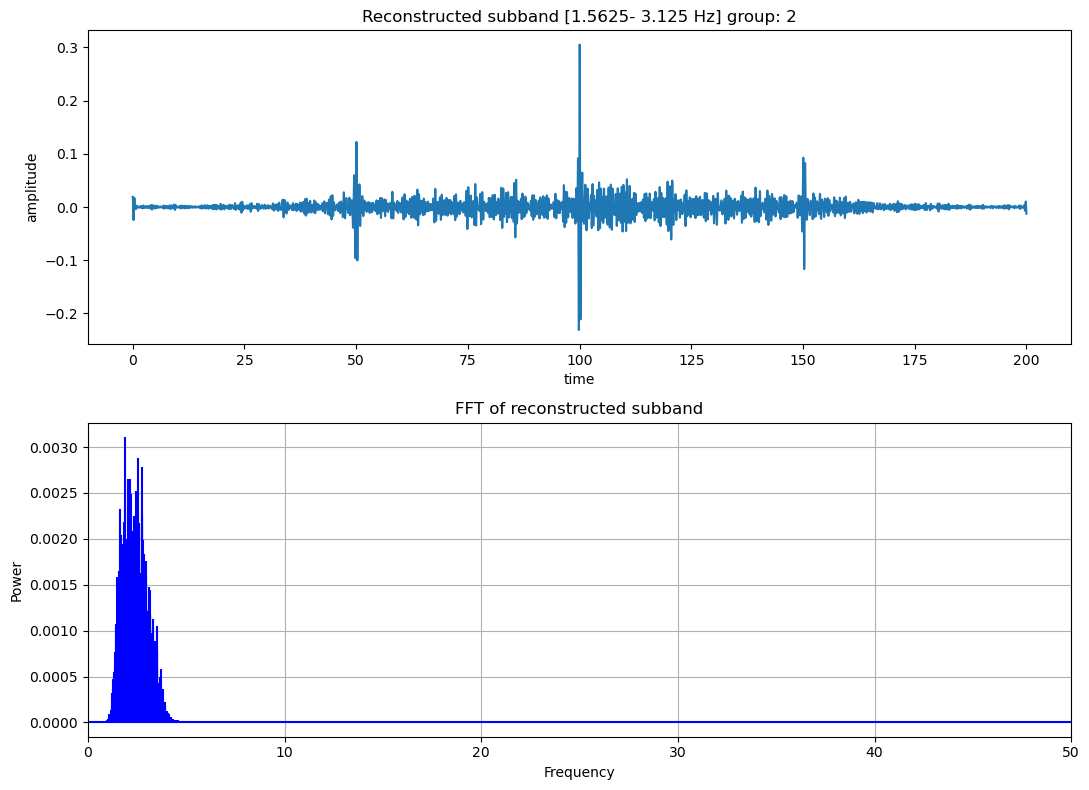

energy of recovered signal: 0.0002731300920022798
kurtosis of recovered signal: 71.73998009835756
crest factor of recovered signal: 3.82434523683115

energy of node coefficients: 0.008464360079128909
kurtosis of node coefficients: 23.881188674628167
crest factor of node coefficients: 9.506110599525336


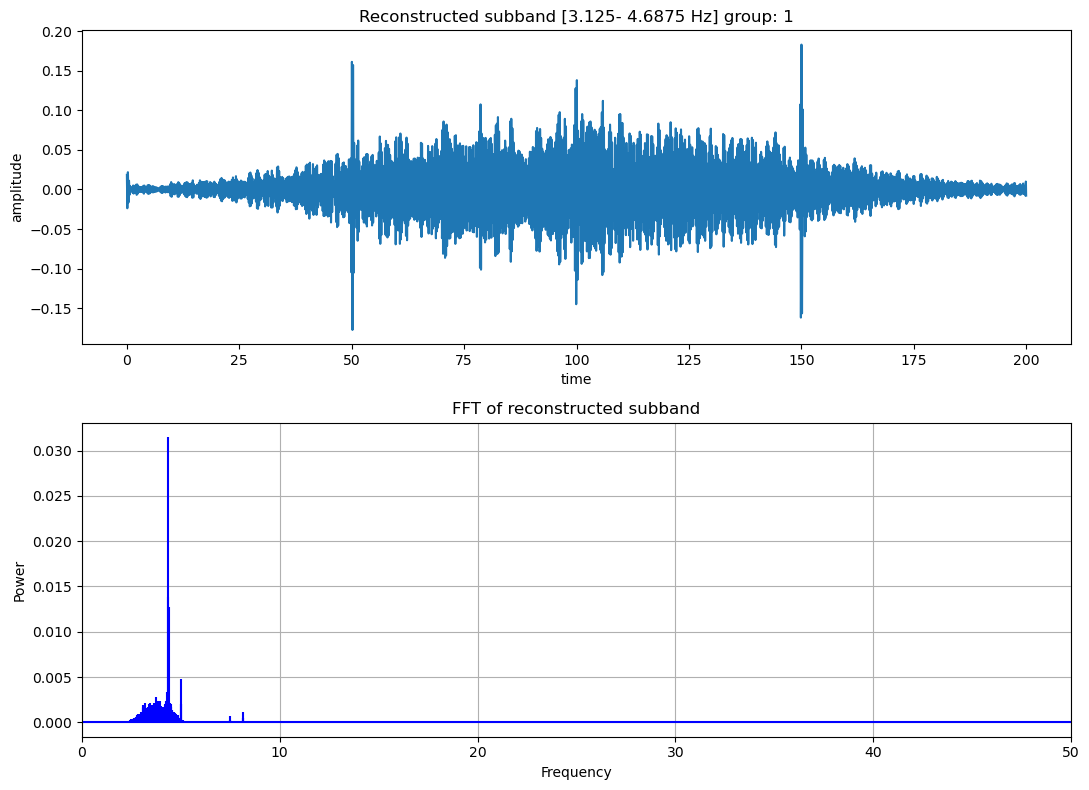

energy of recovered signal: 0.0009355970051034074
kurtosis of recovered signal: 1.718253115873214
crest factor of recovered signal: -5.970873220868426

energy of node coefficients: 0.028483376468860382
kurtosis of node coefficients: 1.3905788155404082
crest factor of node coefficients: 5.288190764847269


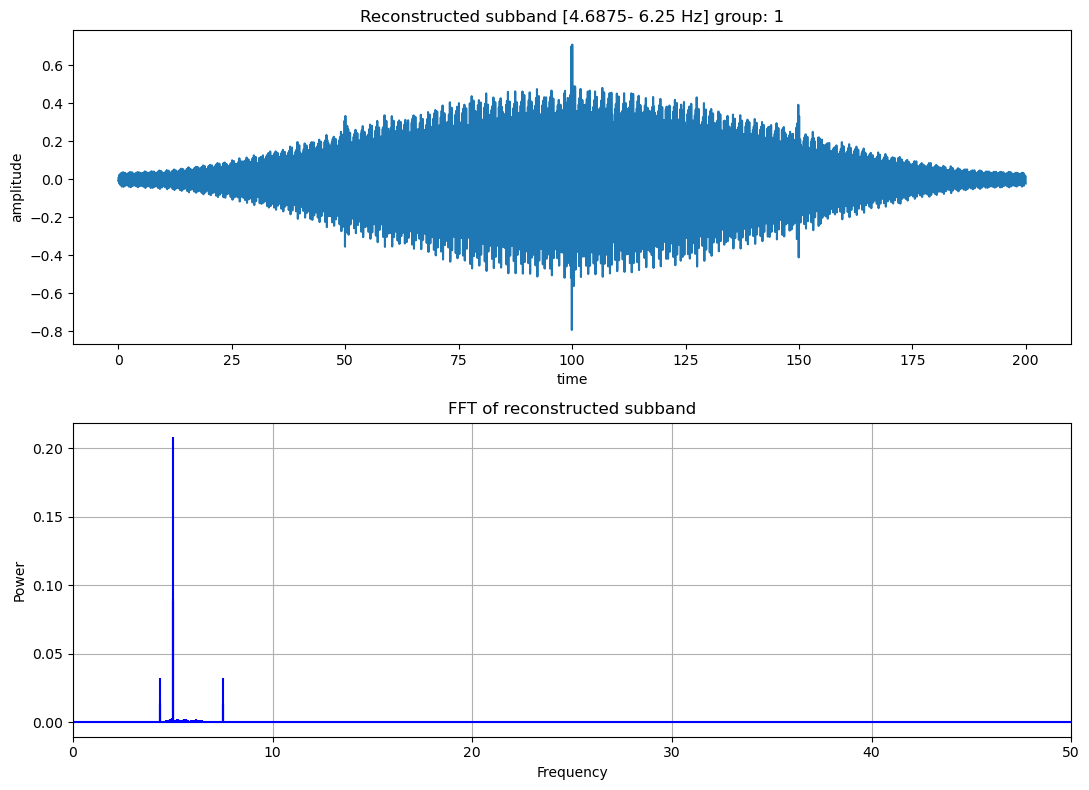

energy of recovered signal: 0.03135216778630586
kurtosis of recovered signal: 0.09787269822798006
crest factor of recovered signal: -8.488699755894466

energy of node coefficients: 0.9477359136078651
kurtosis of node coefficients: 0.03251430219742746
crest factor of node coefficients: 9.9361185355169


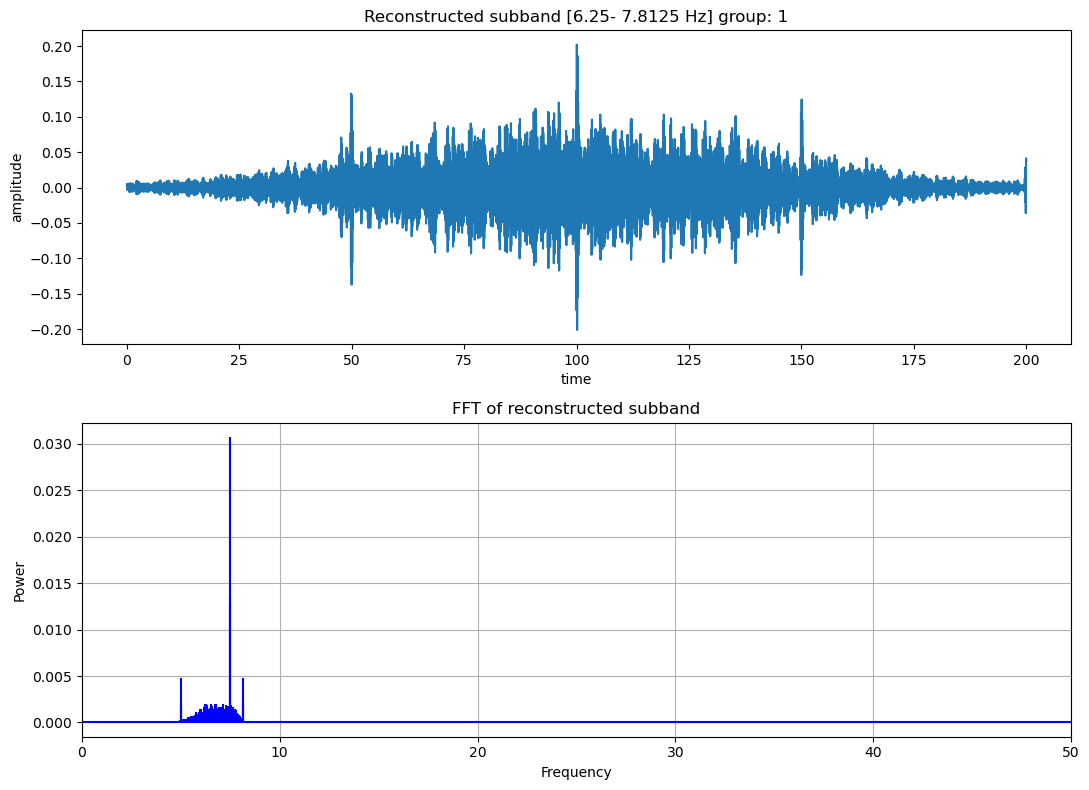

energy of recovered signal: 0.0008755179443553615
kurtosis of recovered signal: 2.0490719304729454
crest factor of recovered signal: -4.8150279938462806

energy of node coefficients: 0.0266509200741267
kurtosis of node coefficients: 1.2453054406400375
crest factor of node coefficients: 4.226667564899831


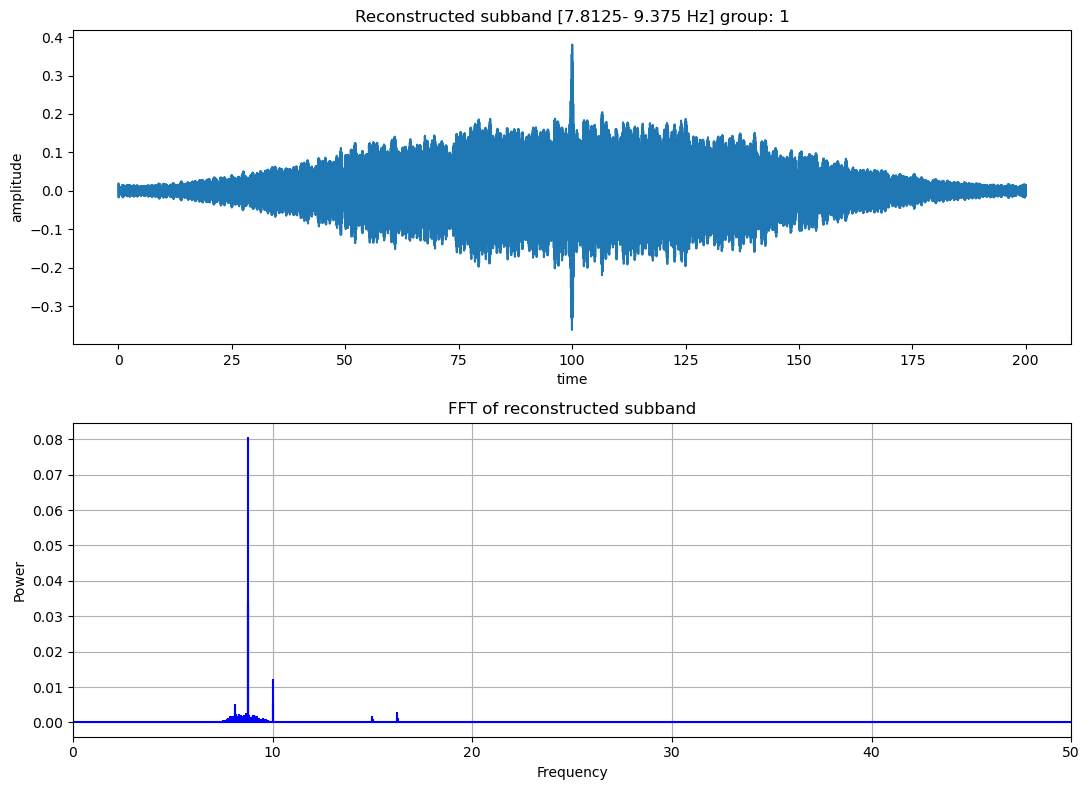

energy of recovered signal: 0.004792566045771798
kurtosis of recovered signal: 0.36576524651182174
crest factor of recovered signal: -6.70003802273737

energy of node coefficients: 0.14504446830110476
kurtosis of node coefficients: 0.5052623039492872
crest factor of node coefficients: 9.21211635397533


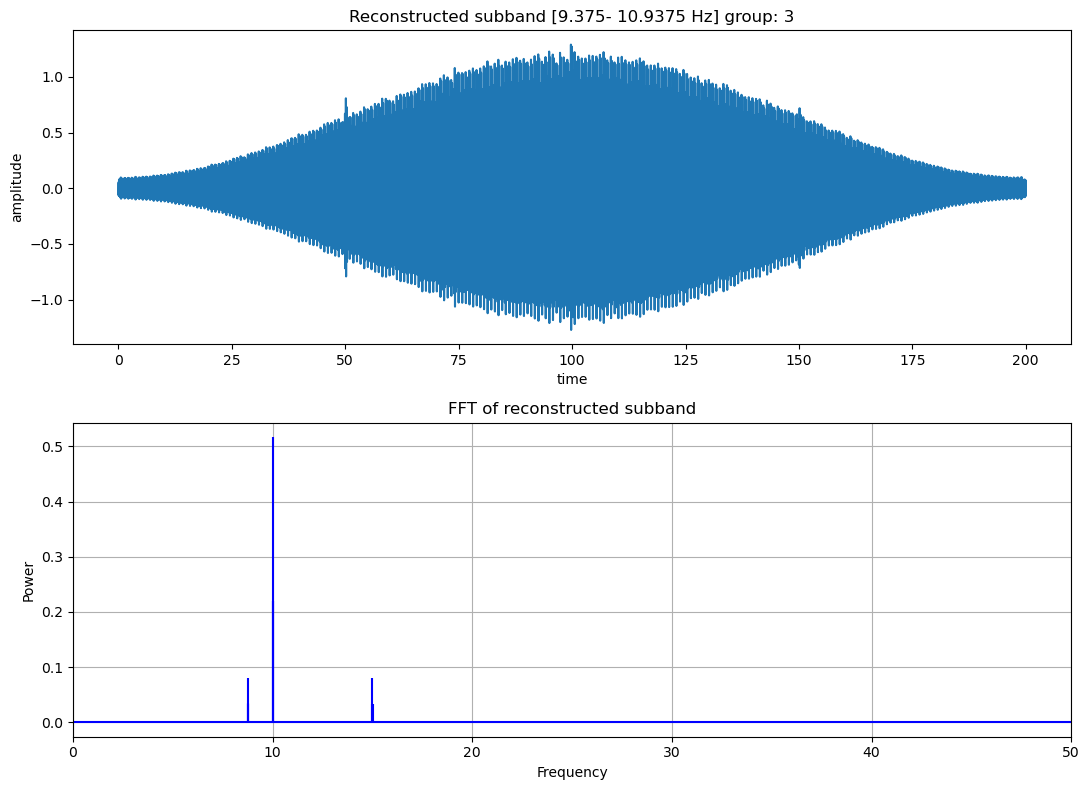

energy of recovered signal: 0.19089358869212866
kurtosis of recovered signal: -0.02274721757455067
crest factor of recovered signal: -12.101767986827943

energy of node coefficients: 5.7714946989639415
kurtosis of node coefficients: -0.11327312503111076
crest factor of node coefficients: 11.257308759832112


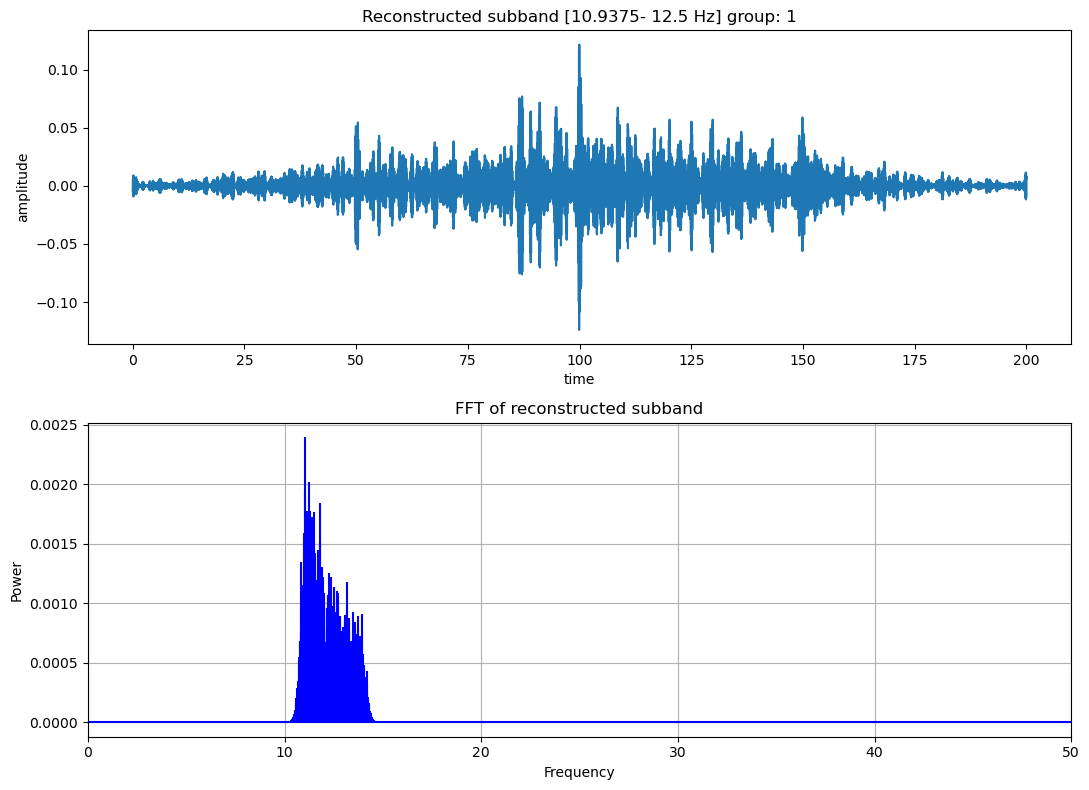

energy of recovered signal: 0.00015680242908620718
kurtosis of recovered signal: 8.110755467898388
crest factor of recovered signal: -1.595542382932125

energy of node coefficients: 0.005197577605893679
kurtosis of node coefficients: 5.136923263062517
crest factor of node coefficients: 4.880775158407781


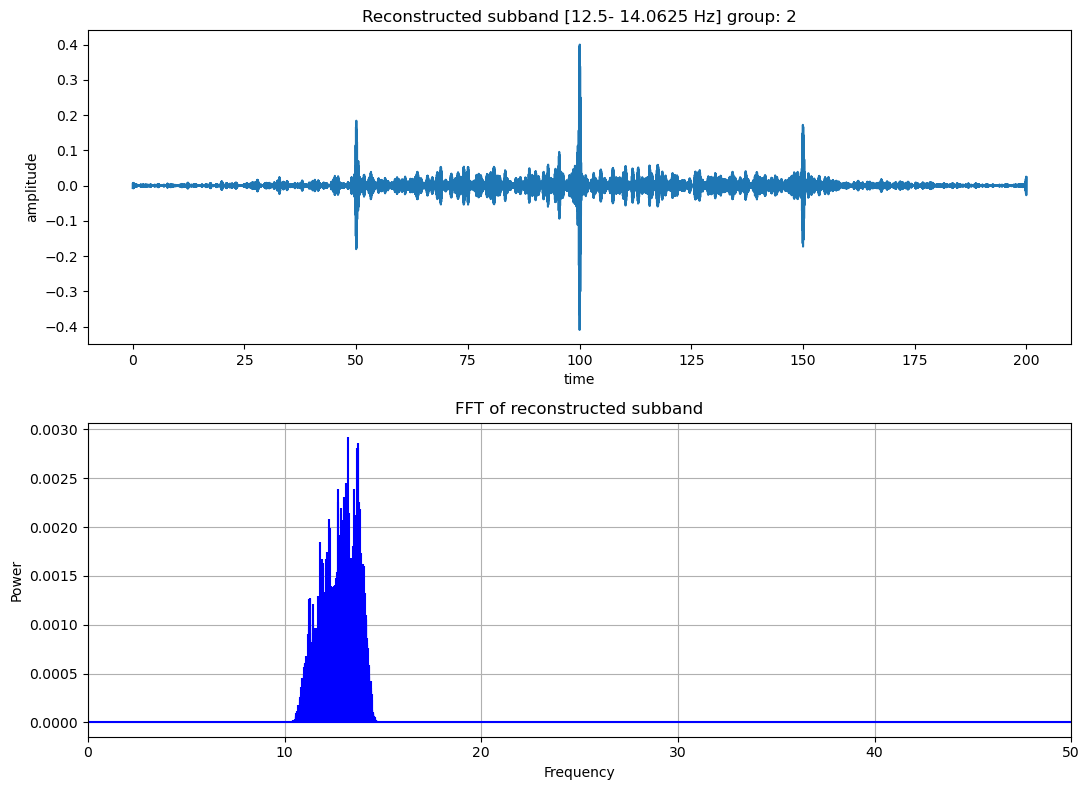

energy of recovered signal: 0.0003236083631897
kurtosis of recovered signal: 125.8437899170718
crest factor of recovered signal: 5.6435090452011245

energy of node coefficients: 0.009826750706767327
kurtosis of node coefficients: 40.706595325788655
crest factor of node coefficients: 11.554169624073594


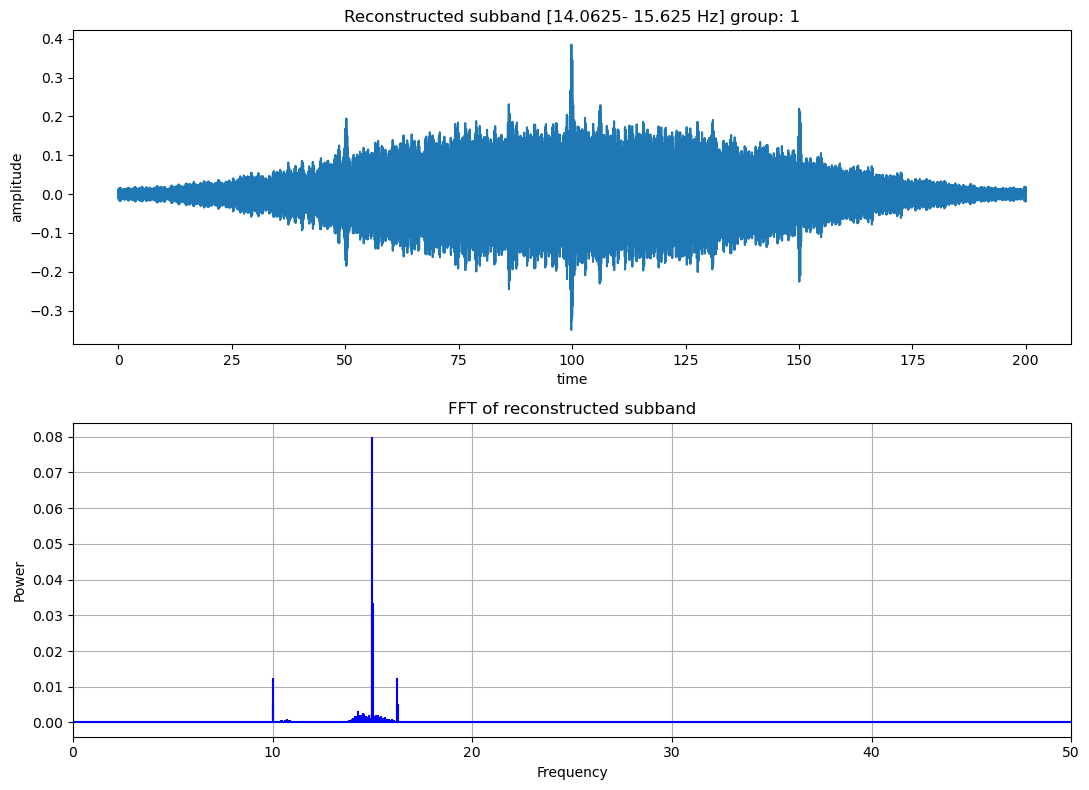

energy of recovered signal: 0.004740766087088476
kurtosis of recovered signal: 0.37618053004505203
crest factor of recovered signal: -6.555669089775274

energy of node coefficients: 0.143365336389907
kurtosis of node coefficients: 0.08590748280638971
crest factor of node coefficients: 6.877519234888312


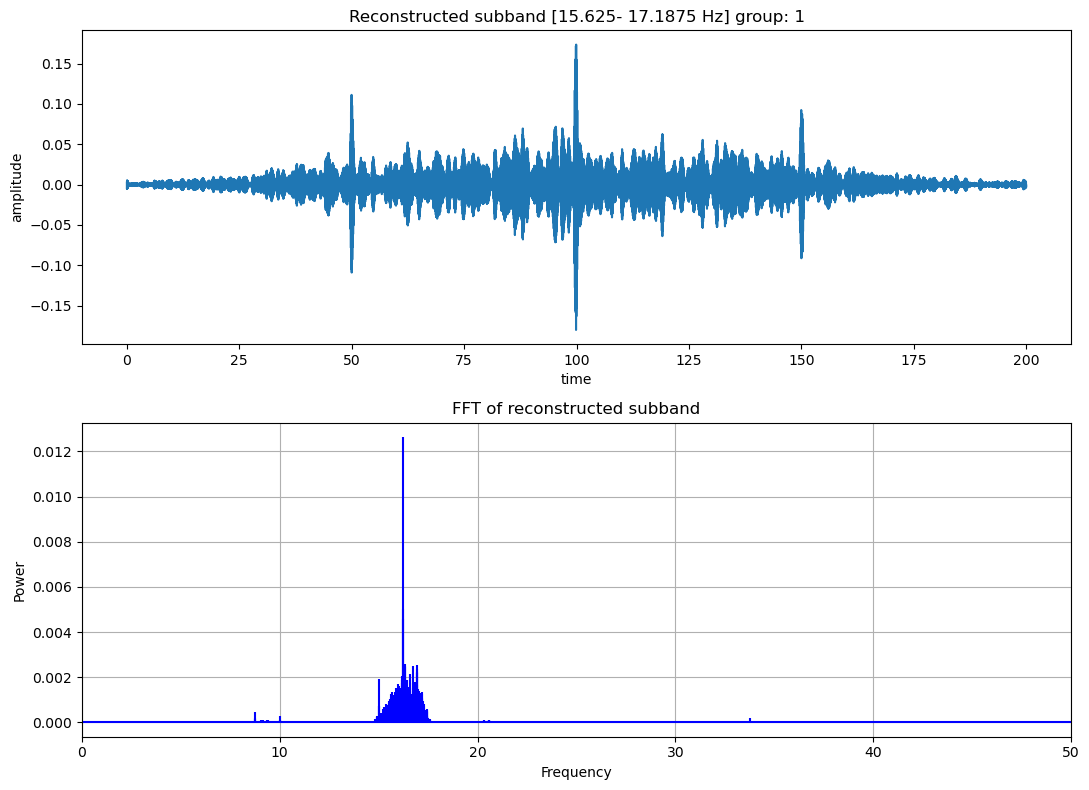

energy of recovered signal: 0.0002841072627803591
kurtosis of recovered signal: 10.332959568422451
crest factor of recovered signal: -0.9195342493289602

energy of node coefficients: 0.008598268056748657
kurtosis of node coefficients: 6.823890900497286
crest factor of node coefficients: 6.63278641222985


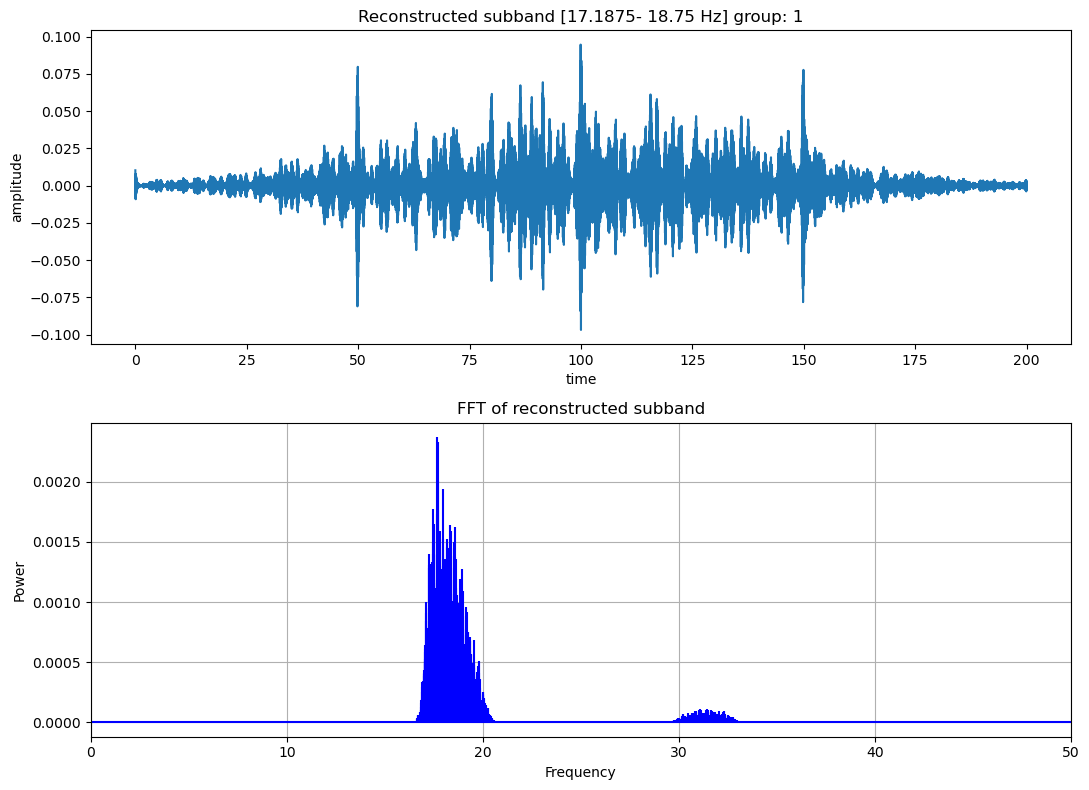

energy of recovered signal: 0.00015106159265859952
kurtosis of recovered signal: 5.597893553975474
crest factor of recovered signal: -3.576573002031775

energy of node coefficients: 0.004573539858596427
kurtosis of node coefficients: 6.317400162923491
crest factor of node coefficients: 4.815368542276409


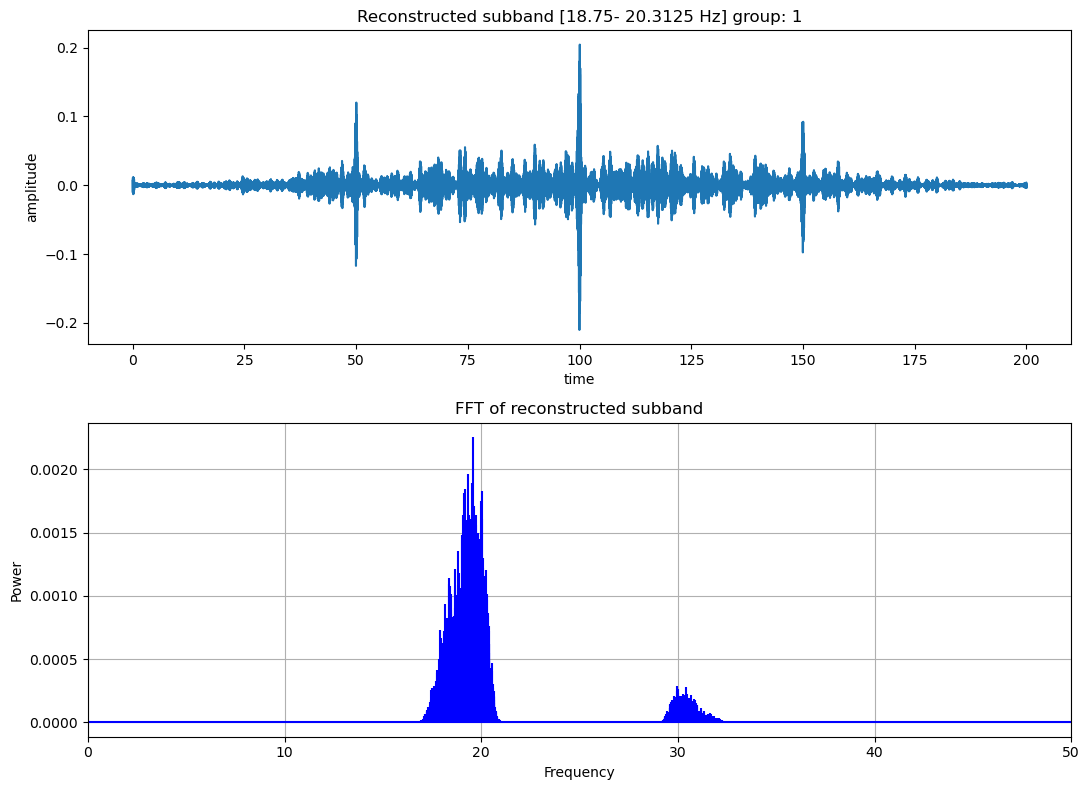

energy of recovered signal: 0.00016585744254888596
kurtosis of recovered signal: 33.50783416907767
crest factor of recovered signal: 2.7580379460245052

energy of node coefficients: 0.005039121769111574
kurtosis of node coefficients: 20.813174537725416
crest factor of node coefficients: 8.853214959611567


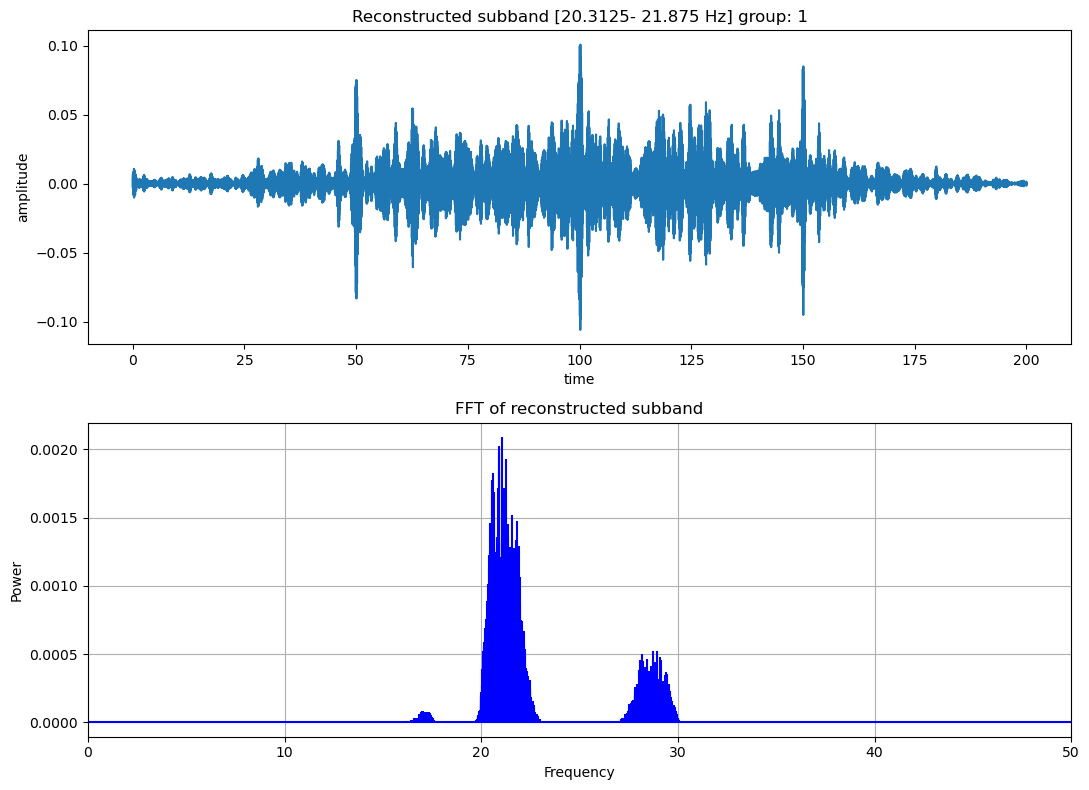

energy of recovered signal: 0.00014654352698927864
kurtosis of recovered signal: 6.525124307888705
crest factor of recovered signal: -2.6496209875654957

energy of node coefficients: 0.00444553722764847
kurtosis of node coefficients: 6.808582874018116
crest factor of node coefficients: 5.249350001138199


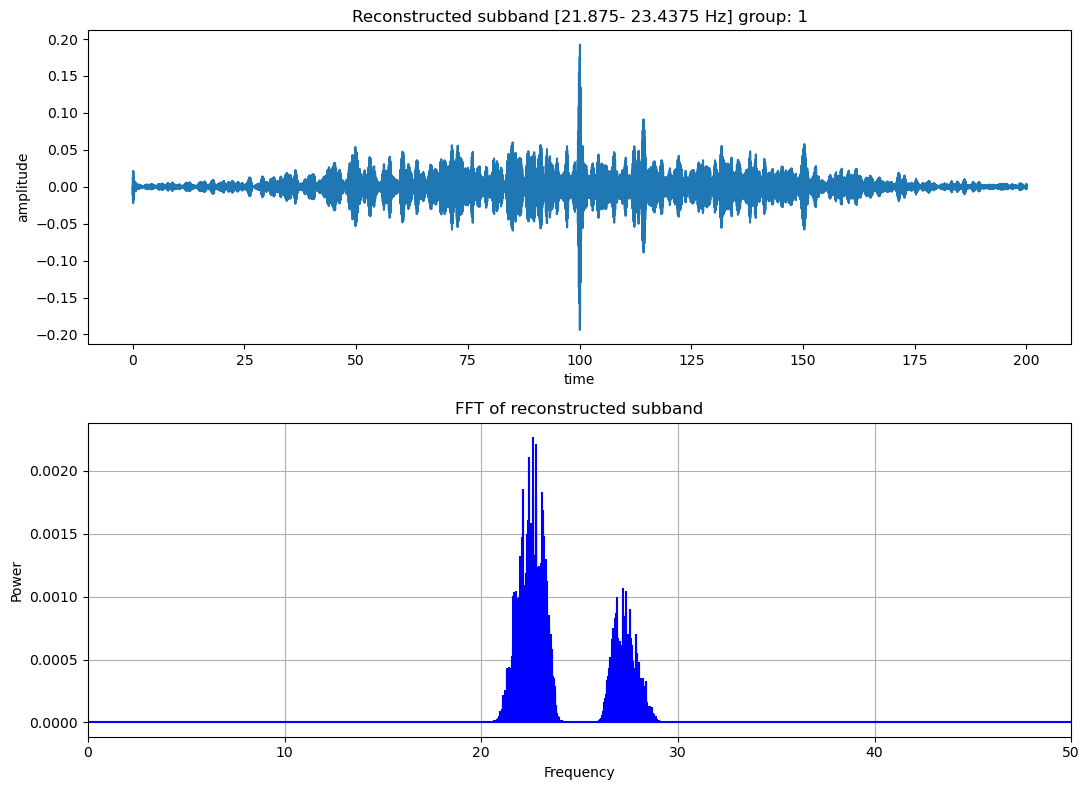

energy of recovered signal: 0.00016753138674185667
kurtosis of recovered signal: 19.56091638188729
crest factor of recovered signal: 2.0054952638690593

energy of node coefficients: 0.005140331078787367
kurtosis of node coefficients: 9.314193242725317
crest factor of node coefficients: 7.069557330231236


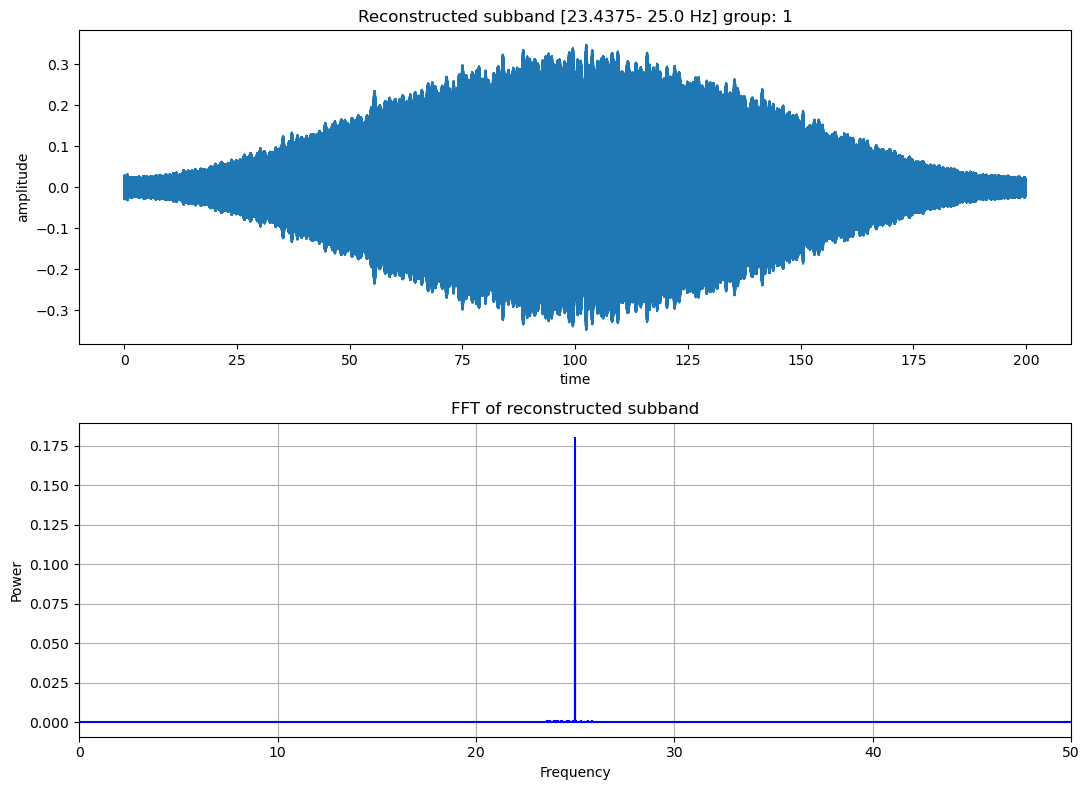

energy of recovered signal: 0.02230759923072443
kurtosis of recovered signal: -0.6098477152165187
crest factor of recovered signal: -14.14670760454679

energy of node coefficients: 0.6745583803191646
kurtosis of node coefficients: -1.4218059480321803
crest factor of node coefficients: 4.664818700445623


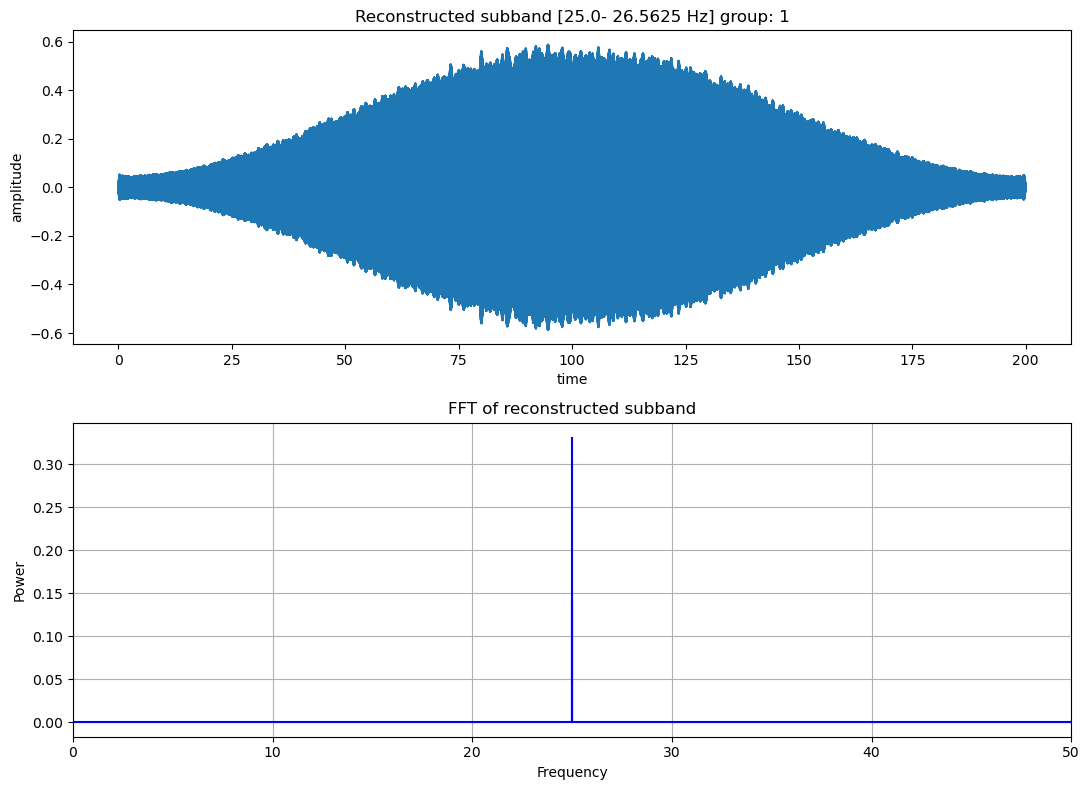

energy of recovered signal: 0.07529111102035731
kurtosis of recovered signal: -0.6377820096365623
crest factor of recovered signal: -14.894094053923435

energy of node coefficients: 2.2765893311157206
kurtosis of node coefficients: -1.4778473016207208
crest factor of node coefficients: 6.789474441375657


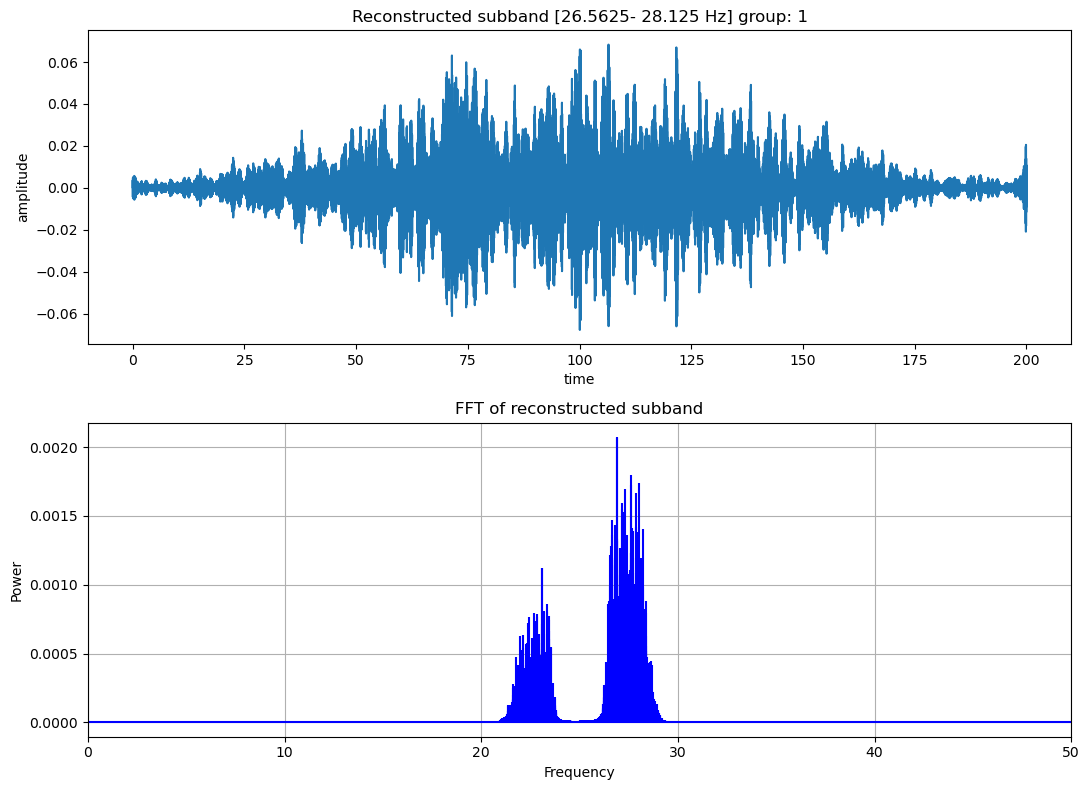

energy of recovered signal: 0.0001474454981526696
kurtosis of recovered signal: 3.5263674710588546
crest factor of recovered signal: -6.497044260807032

energy of node coefficients: 0.004527942328984633
kurtosis of node coefficients: 3.1337849079991953
crest factor of node coefficients: 1.31746164008573


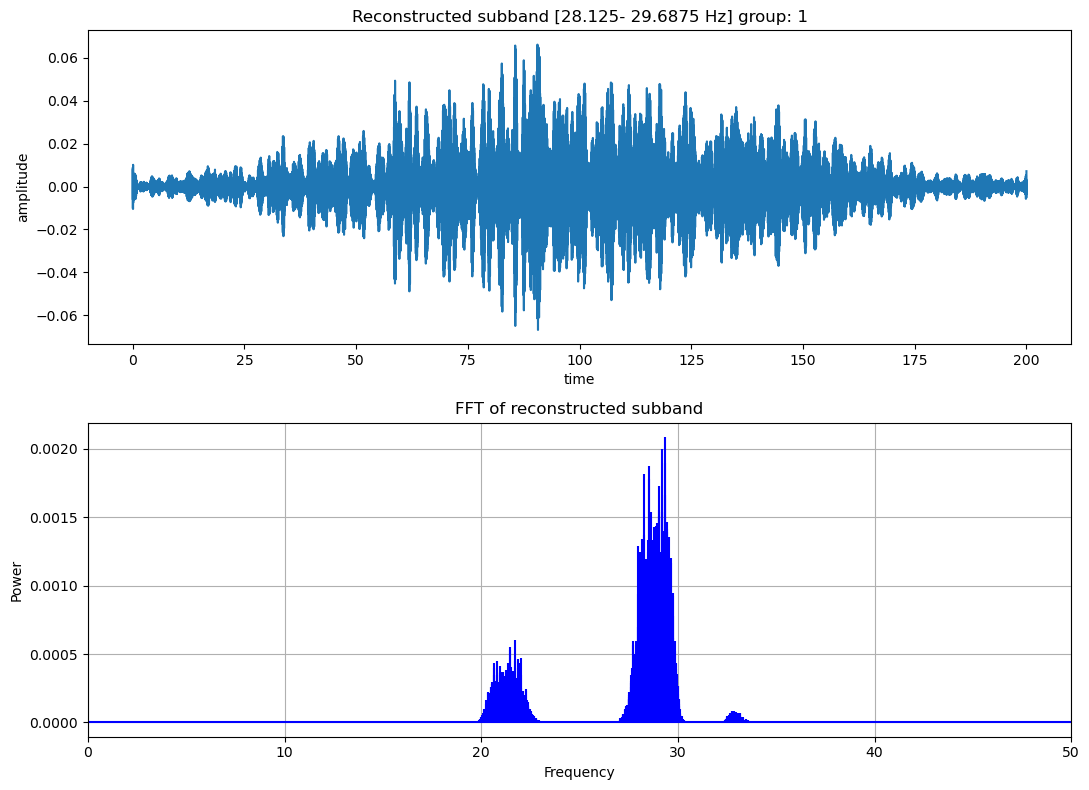

energy of recovered signal: 0.00013368826420753042
kurtosis of recovered signal: 3.0868040078796657
crest factor of recovered signal: -6.265112949241876

energy of node coefficients: 0.004064360057611327
kurtosis of node coefficients: 2.0860508199525736
crest factor of node coefficients: 0.7099874021330826


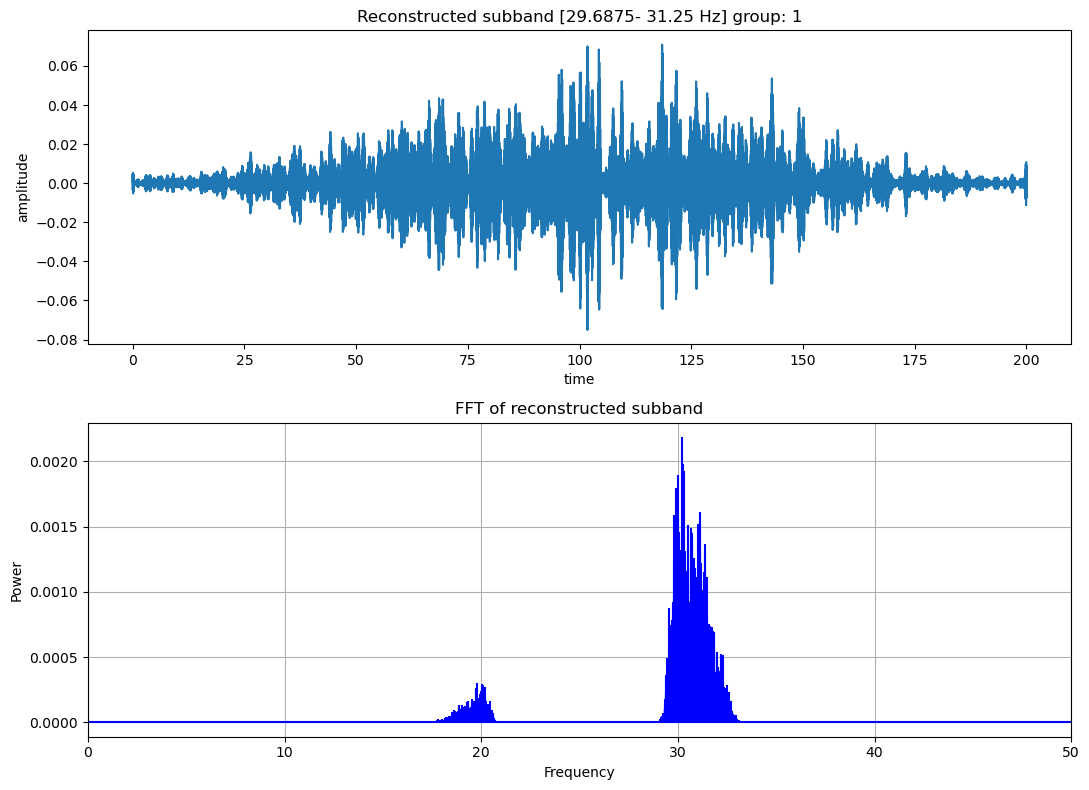

energy of recovered signal: 0.00012792328375317143
kurtosis of recovered signal: 3.900066447465771
crest factor of recovered signal: -5.060488560599198

energy of node coefficients: 0.003886517225701971
kurtosis of node coefficients: 2.187103435657524
crest factor of node coefficients: 0.8961024537347244


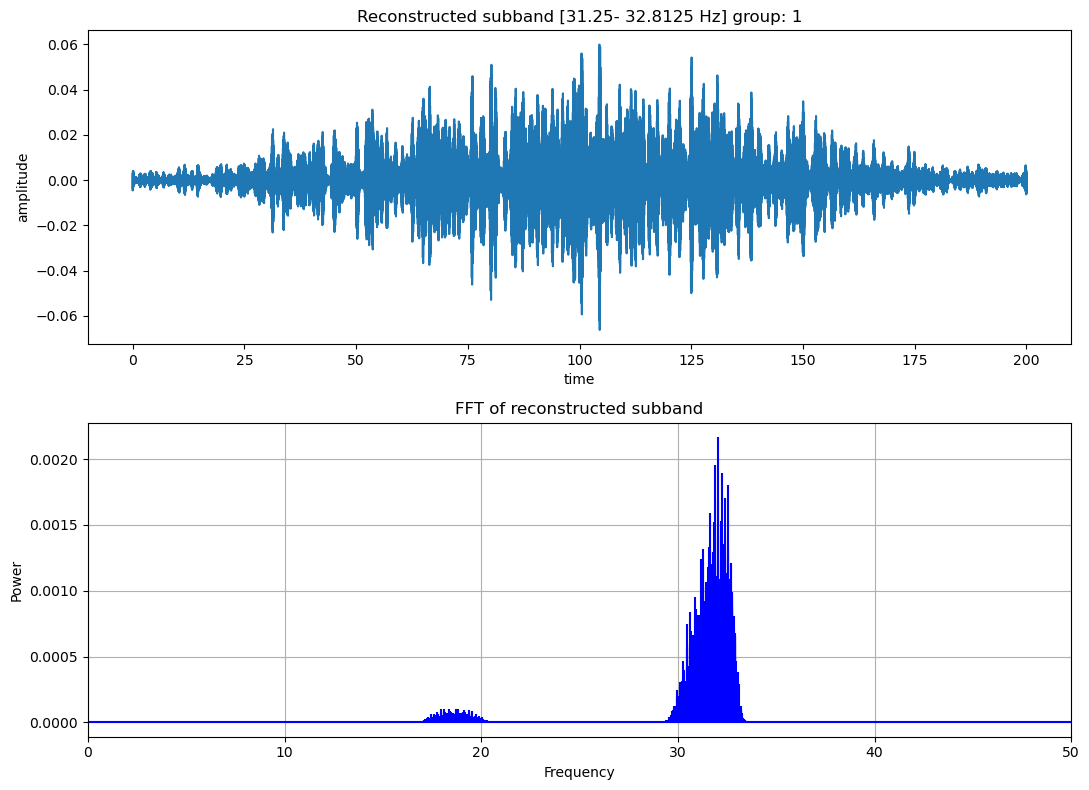

energy of recovered signal: 0.00011819850546784669
kurtosis of recovered signal: 2.752795100711885
crest factor of recovered signal: -5.80620521985364

energy of node coefficients: 0.0035950803242113917
kurtosis of node coefficients: 1.9392335198214266
crest factor of node coefficients: -0.359424841786944


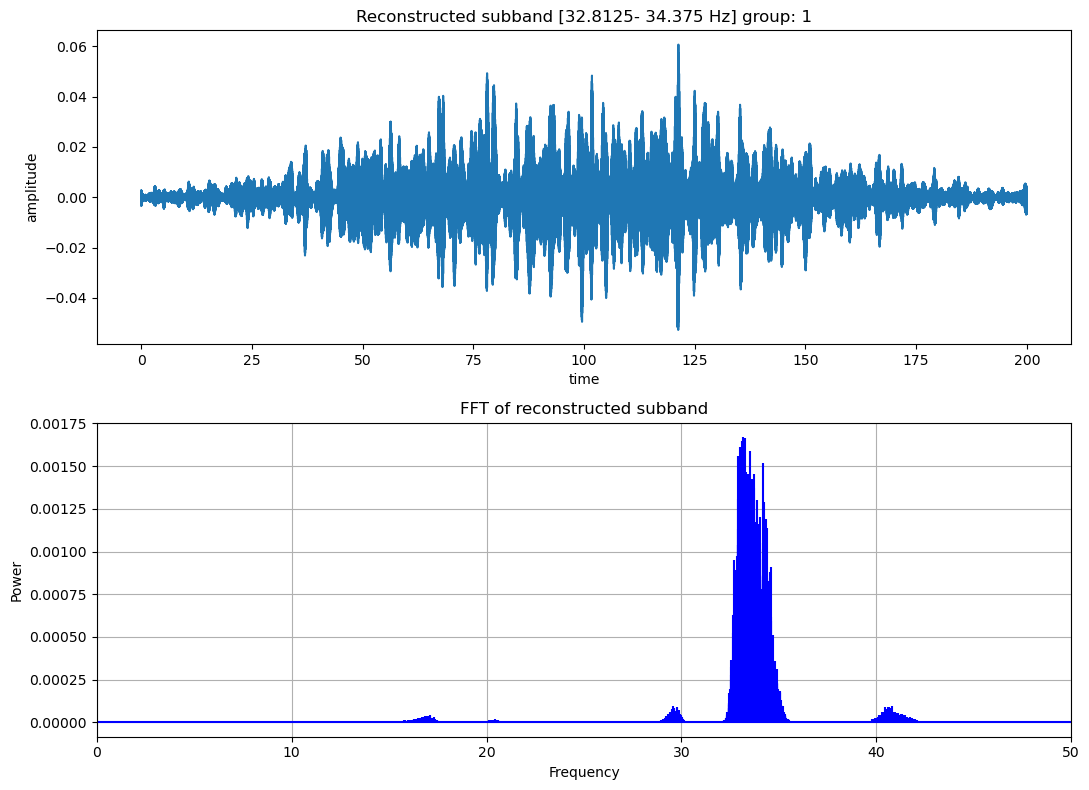

energy of recovered signal: 0.00011029208405993712
kurtosis of recovered signal: 2.363595419498899
crest factor of recovered signal: -6.268763289283603

energy of node coefficients: 0.00340278278689035
kurtosis of node coefficients: 2.452817069631325
crest factor of node coefficients: 0.5384771779943203


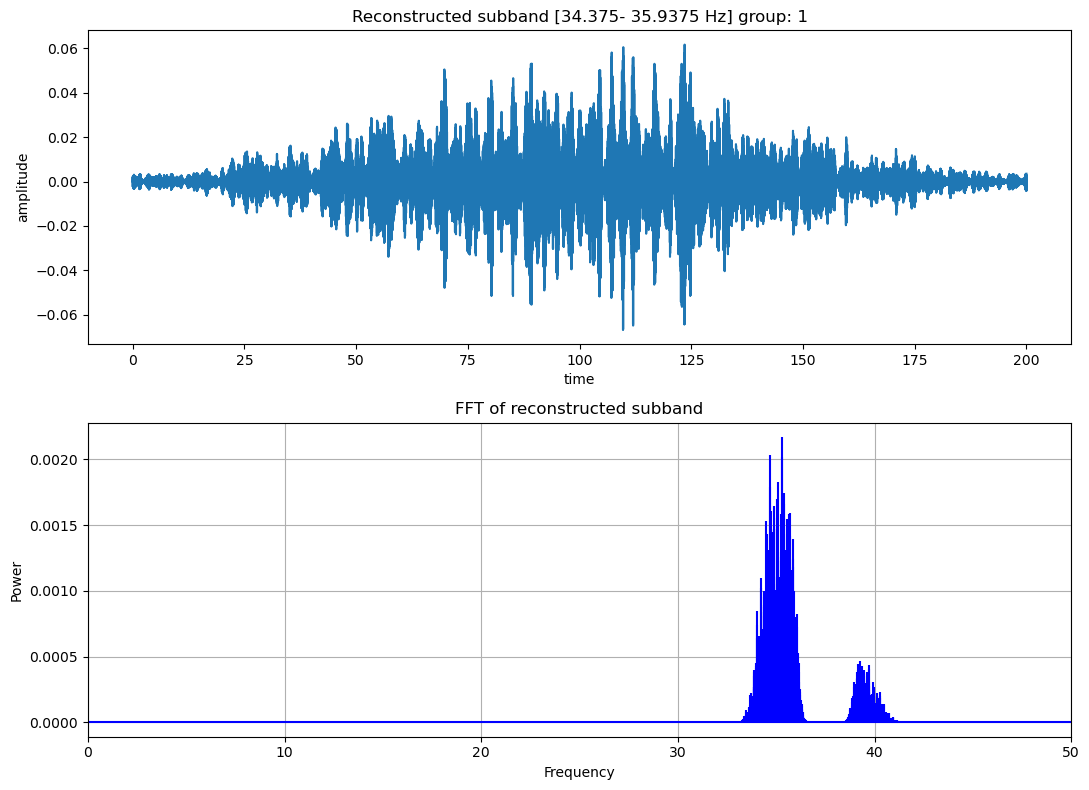

energy of recovered signal: 0.00012583667587436173
kurtosis of recovered signal: 3.4684432151153572
crest factor of recovered signal: -6.008314519035306

energy of node coefficients: 0.00380788032887239
kurtosis of node coefficients: 2.909247453525108
crest factor of node coefficients: 0.0438453562272354


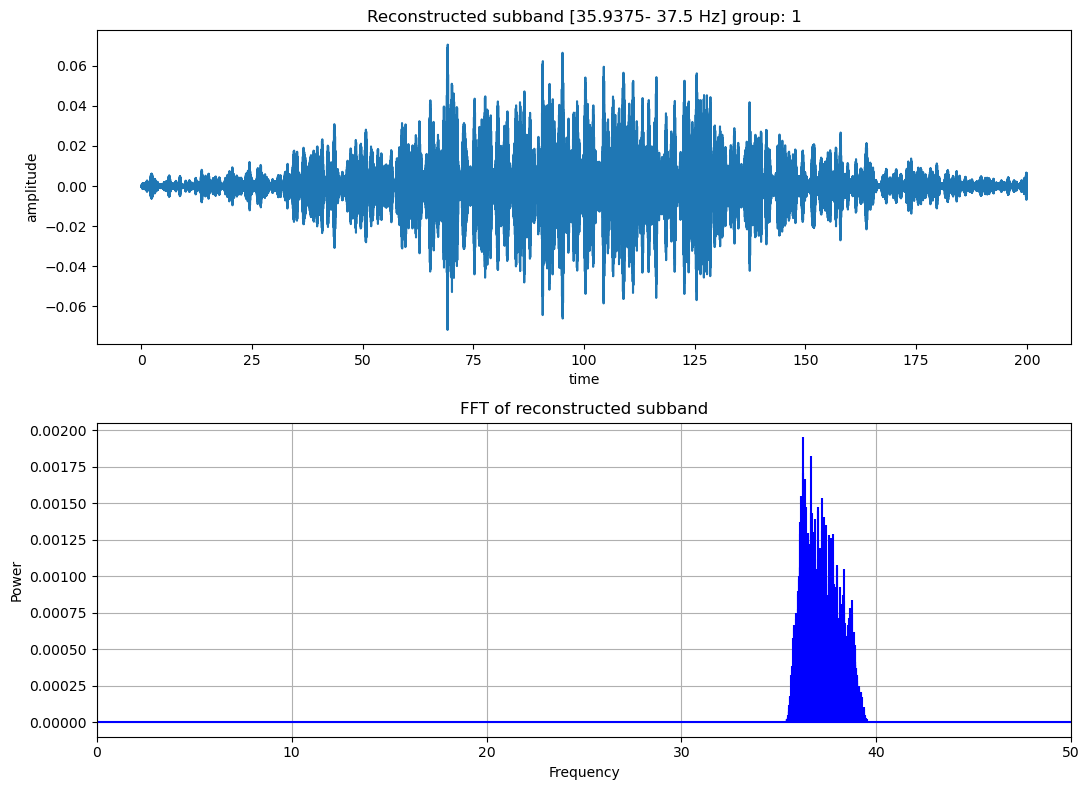

energy of recovered signal: 0.00013746142958654555
kurtosis of recovered signal: 4.134129724758842
crest factor of recovered signal: -5.7778121721870885

energy of node coefficients: 0.004161901154348412
kurtosis of node coefficients: 2.8442784044564675
crest factor of node coefficients: 1.0529668576960138


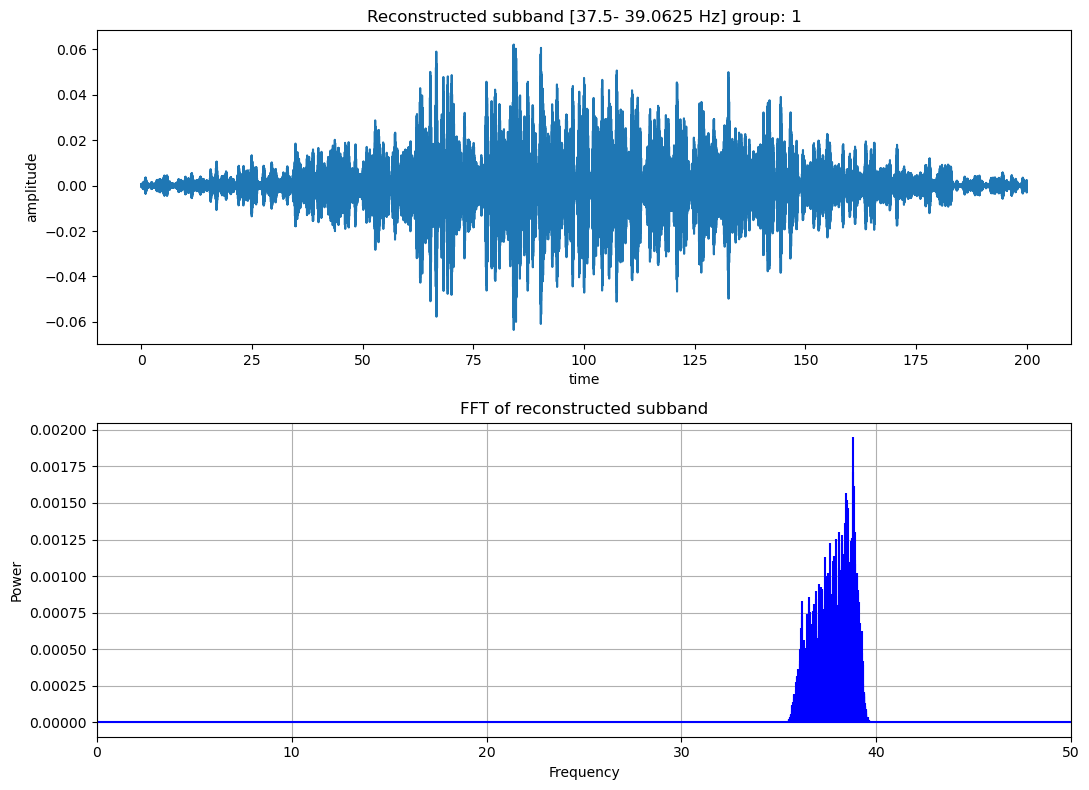

energy of recovered signal: 0.00011622331156704213
kurtosis of recovered signal: 3.8682896358563523
crest factor of recovered signal: -6.099078470490921

energy of node coefficients: 0.00351408425448273
kurtosis of node coefficients: 2.524675450109461
crest factor of node coefficients: 0.7428447686536855


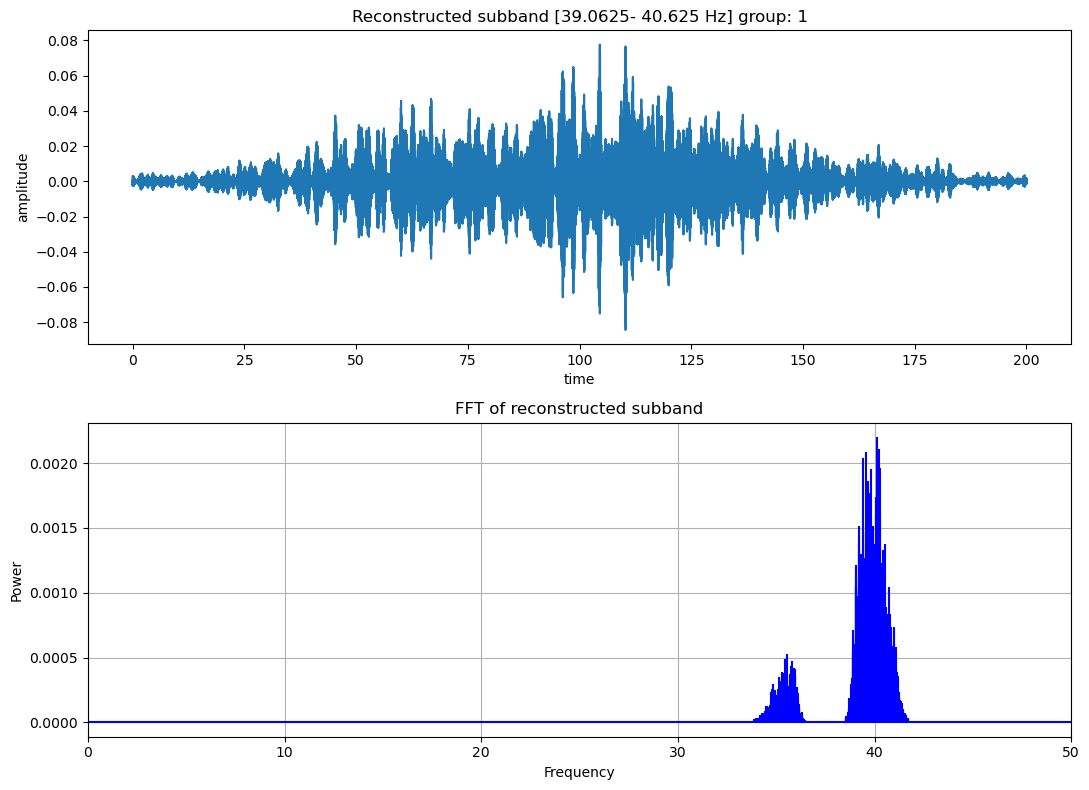

energy of recovered signal: 0.00014459854301689283
kurtosis of recovered signal: 3.7479101041143155
crest factor of recovered signal: -4.581972657645814

energy of node coefficients: 0.004371493058312598
kurtosis of node coefficients: 2.6248187135668832
crest factor of node coefficients: 1.556520025053805


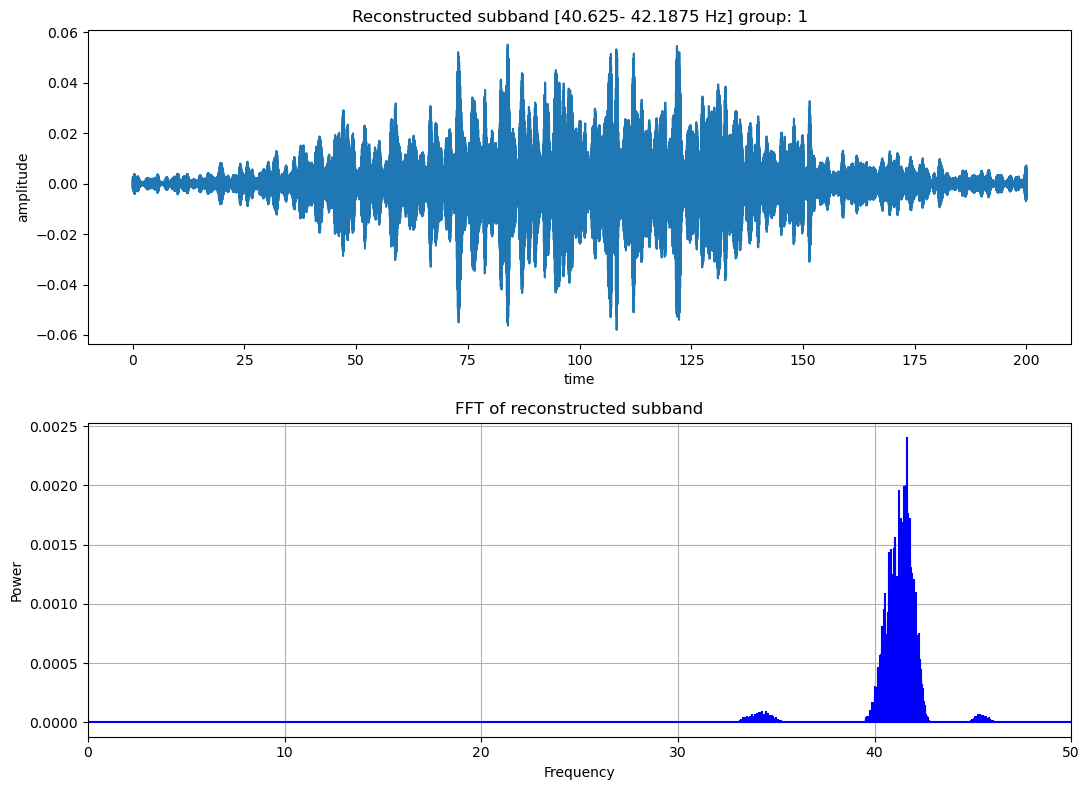

energy of recovered signal: 0.00012902166291002591
kurtosis of recovered signal: 2.8145935759196865
crest factor of recovered signal: -7.343133734591655

energy of node coefficients: 0.003915556122755325
kurtosis of node coefficients: 2.7141905957755386
crest factor of node coefficients: 1.2892250068008992


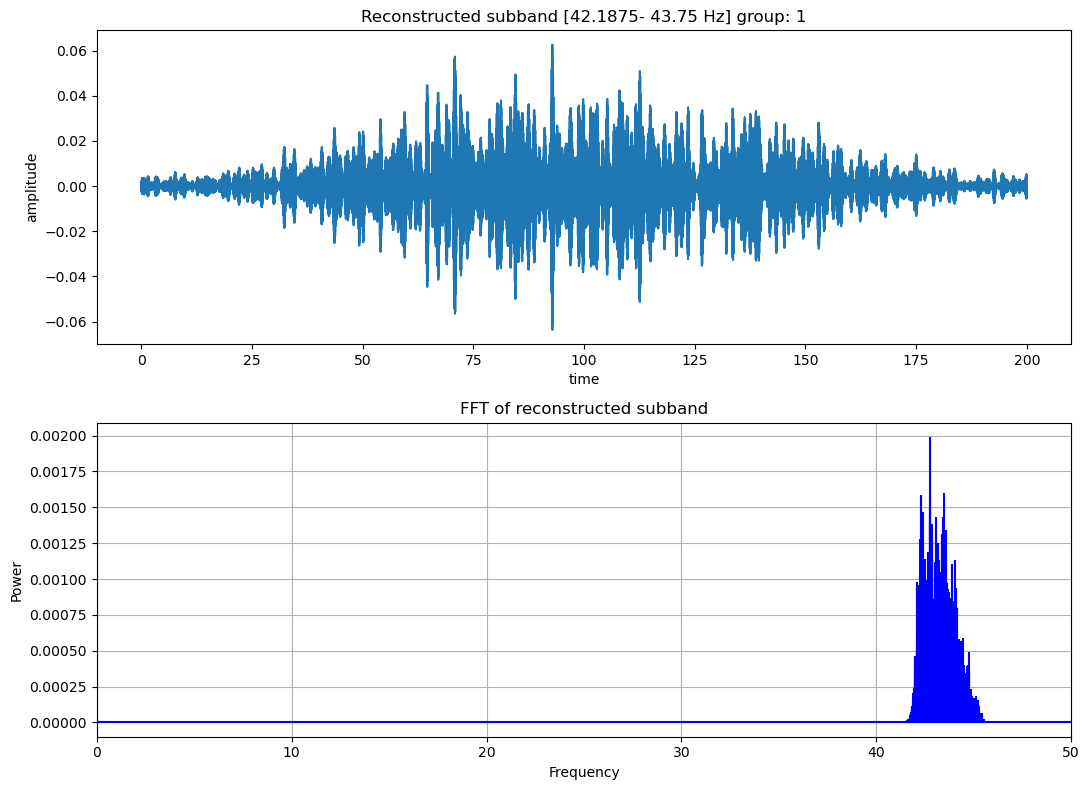

energy of recovered signal: 0.0001075222140973974
kurtosis of recovered signal: 3.145636988355788
crest factor of recovered signal: -5.736778558278452

energy of node coefficients: 0.003256079244512427
kurtosis of node coefficients: 2.4635284716515518
crest factor of node coefficients: 0.6285233672503331


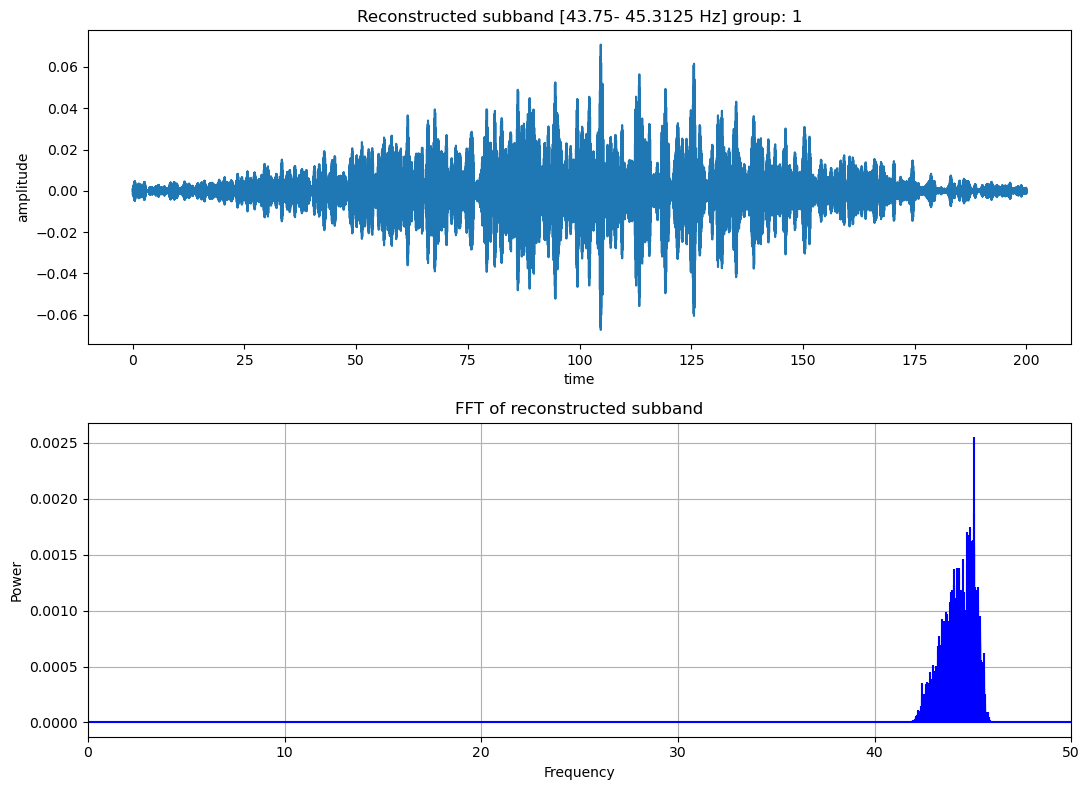

energy of recovered signal: 0.00011670551962849567
kurtosis of recovered signal: 3.6010415243007303
crest factor of recovered signal: -5.173322604508628

energy of node coefficients: 0.0035331578338151223
kurtosis of node coefficients: 2.476755309356893
crest factor of node coefficients: 1.2201032516685286


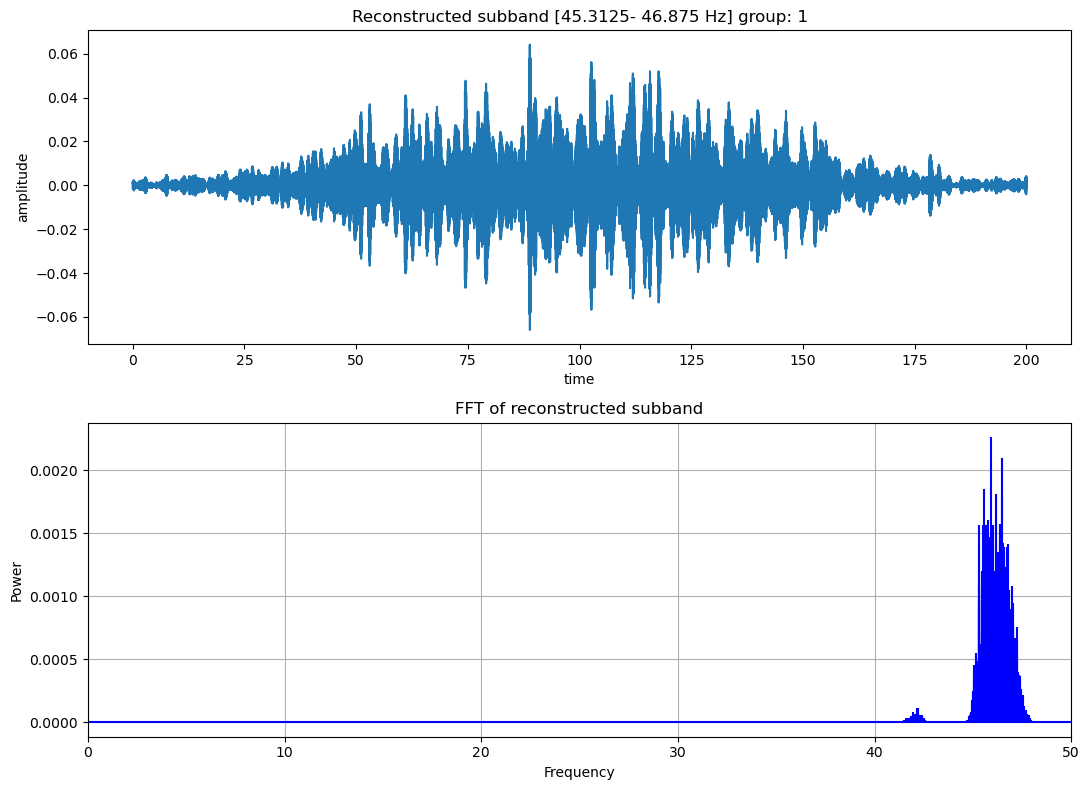

energy of recovered signal: 0.00013420037761391083
kurtosis of recovered signal: 2.585915096913716
crest factor of recovered signal: -6.404698039956721

energy of node coefficients: 0.004060520911762319
kurtosis of node coefficients: 2.35168961101951
crest factor of node coefficients: 0.43379812523899597


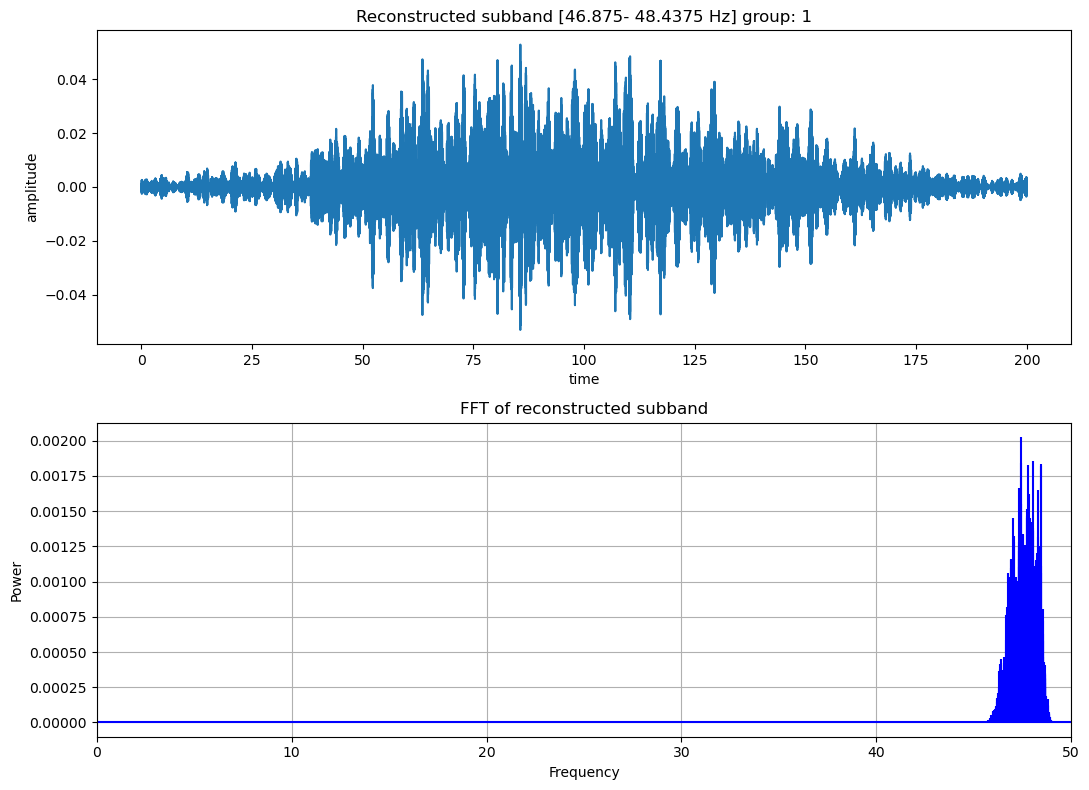

energy of recovered signal: 0.000126018712721666
kurtosis of recovered signal: 2.1390481809325568
crest factor of recovered signal: -8.012595994798154

energy of node coefficients: 0.00381195145701716
kurtosis of node coefficients: 2.2148616100017895
crest factor of node coefficients: 0.54507178190328


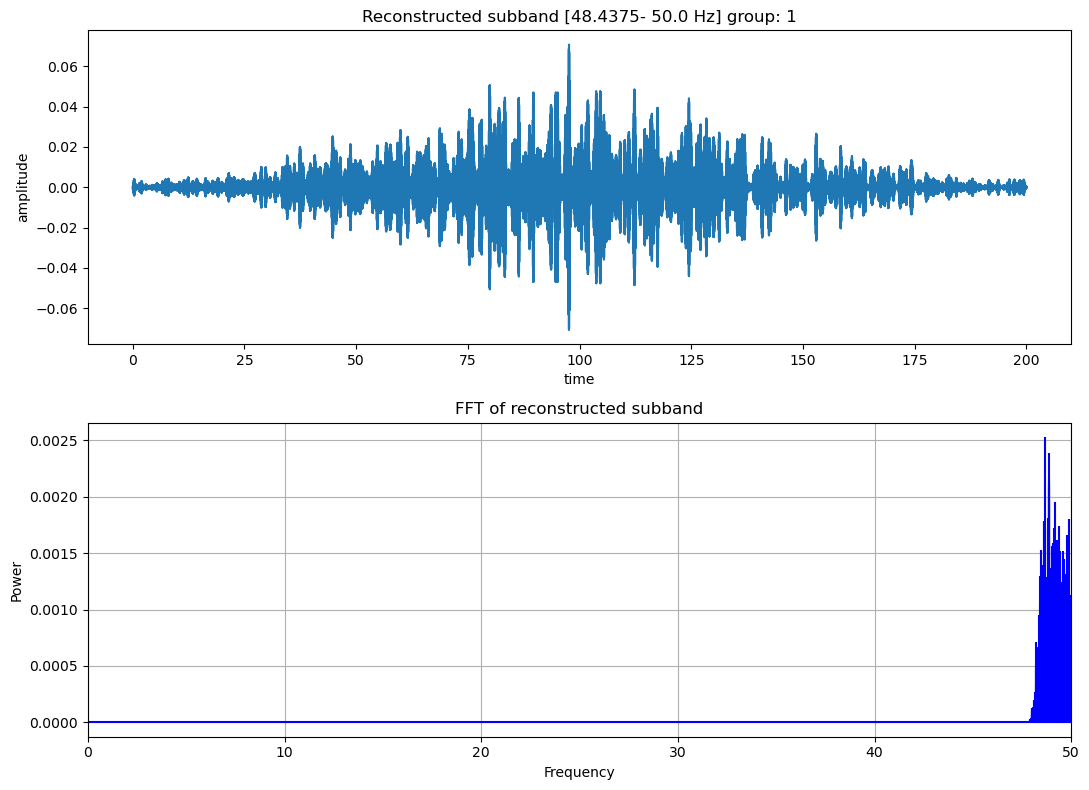

energy of recovered signal: 0.00014282015585345863
kurtosis of recovered signal: 3.225636961795738
crest factor of recovered signal: -6.048627106284503

energy of node coefficients: 0.004323784240824341
kurtosis of node coefficients: 3.185310534276651
crest factor of node coefficients: 1.3737785791814874


In [18]:
plot_reconstructions(rec, group=reassigned_labels)
# plot_reconstructions(rec, group=reassigned_pca_labels)